In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Python executable: d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\.venv\Scripts\python.exe


In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATASET_ROOT = PROJECT_ROOT / "dataset" / "archive"

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATASET_ROOT)
print("Dataset exists:", DATASET_ROOT.exists())

Project root: d:\Documents\Ml project\Bangladesh_License_Plate_Recognition
Dataset root: d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\archive
Dataset exists: True


In [3]:
from pathlib import Path

tasks = [
    "License Plate Localization",
    "Character Recognition"
]

splits = ["train", "validation", "test"]

for task in tasks:
    print(f"\n{'=' * 60}")
    print(task)
    print("=" * 60)

    for split in splits:
        folder = DATASET_ROOT / task / split

        images = (
            list(folder.glob("*.jpg"))
            + list(folder.glob("*.jpeg"))
            + list(folder.glob("*.png"))
        )

        xml_files = list(folder.glob("*.xml"))

        print(f"\n{split.upper()}")
        print(f"Images : {len(images)}")
        print(f"XML    : {len(xml_files)}")
        print(f"Total  : {len(list(folder.iterdir()))}")


License Plate Localization

TRAIN
Images : 5687
XML    : 5687
Total  : 11374

VALIDATION
Images : 277
XML    : 277
Total  : 554

TEST
Images : 553
XML    : 553
Total  : 1106

Character Recognition

TRAIN
Images : 3480
XML    : 3480
Total  : 6960

VALIDATION
Images : 363
XML    : 363
Total  : 726

TEST
Images : 218
XML    : 218
Total  : 436


In [4]:
localization_root = DATASET_ROOT / "License Plate Localization"

for split in ["train", "validation", "test"]:
    folder = localization_root / split

    image_files = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    xml_files = list(folder.glob("*.xml"))

    image_stems = {file.stem for file in image_files}
    xml_stems = {file.stem for file in xml_files}

    images_without_xml = image_stems - xml_stems
    xml_without_images = xml_stems - image_stems

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(image_files))
    print("XML files:", len(xml_files))
    print("Images without XML:", len(images_without_xml))
    print("XML without image:", len(xml_without_images))


--- TRAIN ---
Images: 5687
XML files: 5687
Images without XML: 0
XML without image: 0

--- VALIDATION ---
Images: 277
XML files: 277
Images without XML: 0
XML without image: 0

--- TEST ---
Images: 553
XML files: 553
Images without XML: 0
XML without image: 0


In [5]:
import xml.etree.ElementTree as ET

localization_root = DATASET_ROOT / "License Plate Localization"

total_xml = 0
valid_xml = 0
corrupt_xml = []
no_object_xml = []
invalid_boxes = []
object_counts = {}

for split in ["train", "validation", "test"]:
    folder = localization_root / split

    for xml_file in folder.glob("*.xml"):
        total_xml += 1

        try:
            tree = ET.parse(xml_file)
            root = tree.getroot()

            size = root.find("size")

            if size is None:
                corrupt_xml.append((split, xml_file.name, "Missing size"))
                continue

            width = int(size.findtext("width", 0))
            height = int(size.findtext("height", 0))

            objects = root.findall("object")

            if len(objects) == 0:
                no_object_xml.append((split, xml_file.name))

            for obj in objects:
                class_name = obj.findtext("name", "UNKNOWN")
                object_counts[class_name] = object_counts.get(class_name, 0) + 1

                box = obj.find("bndbox")

                if box is None:
                    invalid_boxes.append(
                        (split, xml_file.name, class_name, "Missing bndbox")
                    )
                    continue

                xmin = int(float(box.findtext("xmin", 0)))
                ymin = int(float(box.findtext("ymin", 0)))
                xmax = int(float(box.findtext("xmax", 0)))
                ymax = int(float(box.findtext("ymax", 0)))

                if (
                    xmin < 0
                    or ymin < 0
                    or xmax > width
                    or ymax > height
                    or xmin >= xmax
                    or ymin >= ymax
                ):
                    invalid_boxes.append(
                        (
                            split,
                            xml_file.name,
                            class_name,
                            (xmin, ymin, xmax, ymax),
                            (width, height),
                        )
                    )

            valid_xml += 1

        except Exception as e:
            corrupt_xml.append((split, xml_file.name, str(e)))

print("Total XML files:", total_xml)
print("Successfully parsed XML:", valid_xml)
print("Corrupt/problem XML:", len(corrupt_xml))
print("XML with no objects:", len(no_object_xml))
print("Invalid bounding boxes:", len(invalid_boxes))

print("\nObject classes:")
for class_name, count in sorted(object_counts.items()):
    print(f"{class_name}: {count}")

Total XML files: 6517
Successfully parsed XML: 6517
Corrupt/problem XML: 0
XML with no objects: 1795
Invalid bounding boxes: 6

Object classes:
0: 4795


In [6]:
from collections import Counter

empty_by_split = Counter(split for split, _ in no_object_xml)
invalid_by_split = Counter(item[0] for item in invalid_boxes)

print("EMPTY ANNOTATIONS BY SPLIT")
for split in ["train", "validation", "test"]:
    print(f"{split}: {empty_by_split[split]}")

print("\nINVALID BOXES BY SPLIT")
for split in ["train", "validation", "test"]:
    print(f"{split}: {invalid_by_split[split]}")

print("\nINVALID BOX DETAILS")
for item in invalid_boxes:
    print(item)

print("\nFIRST 10 EMPTY ANNOTATIONS")
for item in no_object_xml[:10]:
    print(item)

EMPTY ANNOTATIONS BY SPLIT
train: 1541
validation: 92
test: 162

INVALID BOXES BY SPLIT
train: 4
validation: 0
test: 2

INVALID BOX DETAILS
('train', 'car-2083_jpg.rf.da5150f59b99e2aec75ac91bb768d5bc.xml', '0', (611, 563, 721, 628), (720, 960))
('train', 'car-5005_jpg.rf.c7d571b3a19afd65d039dcfb3e8a7301.xml', '0', (177, 258, 246, 294), (333, 293))
('train', 'car-6029_jpg.rf.431f6ec20e38f73477c100655891a845.xml', '0', (293, 467, 471, 552), (726, 551))
('train', 'car-6211_jpg.rf.ae3cccf66d4db835b5c2ec1e2cfa4e8c.xml', '0', (180, 336, 308, 405), (467, 404))
('test', 'car-6166_jpg.rf.8ded62055174856e2b6e4e5848d02cd1.xml', '0', (238, 453, 393, 531), (668, 530))
('test', 'car-6207_jpg.rf.e548211f7a6365617c9ff487ae3abb2a.xml', '0', (161, 422, 317, 497), (632, 496))

FIRST 10 EMPTY ANNOTATIONS
('train', '01_jpg.rf.758c08e58644245ef65c68b685f2f014.xml')
('train', '01_jpg.rf.a92b3ff41705844e851ca220036720bd.xml')
('train', '01_jpg.rf.c055bb3bd005985bd325c09e223f40d2.xml')
('train', '01_jpg.rf.e63

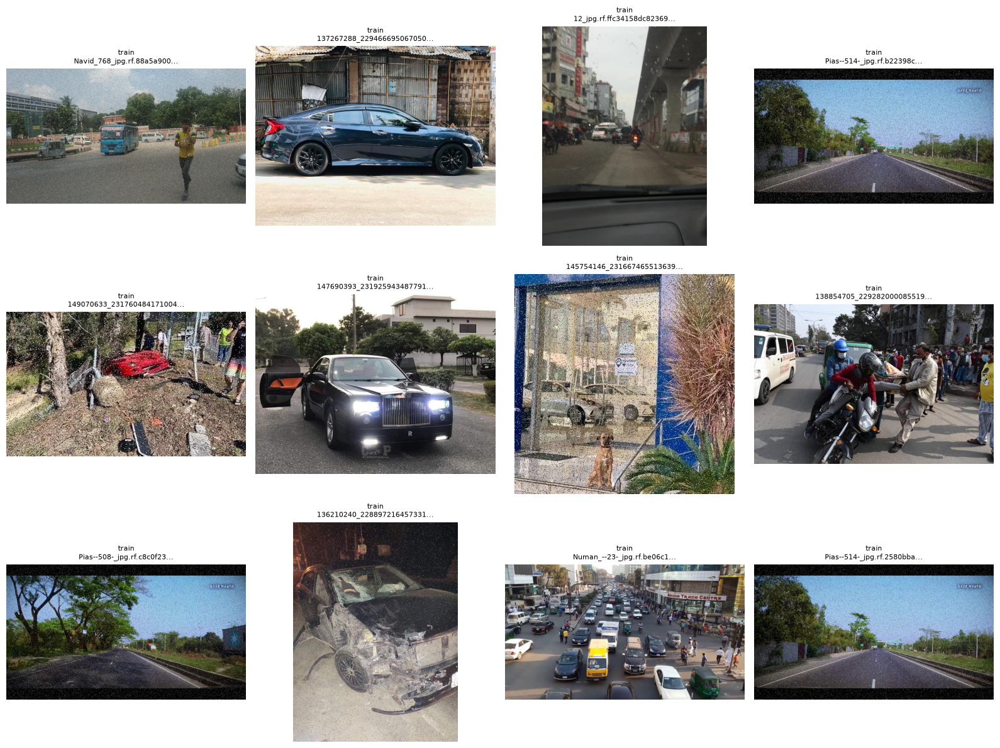

In [9]:
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

samples = random.sample(no_object_xml, min(12, len(no_object_xml)))

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, (split, xml_name) in zip(axes, samples):
    folder = localization_root / split
    stem = Path(xml_name).stem

    image_path = None

    for ext in [".jpg", ".jpeg", ".png"]:
        candidate = folder / f"{stem}{ext}"
        if candidate.exists():
            image_path = candidate
            break

    if image_path:
        image = Image.open(image_path)
        ax.imshow(image)
        ax.set_title(f"{split}\n{image_path.name[:25]}...", fontsize=8)

    ax.axis("off")

plt.tight_layout()
plt.show()

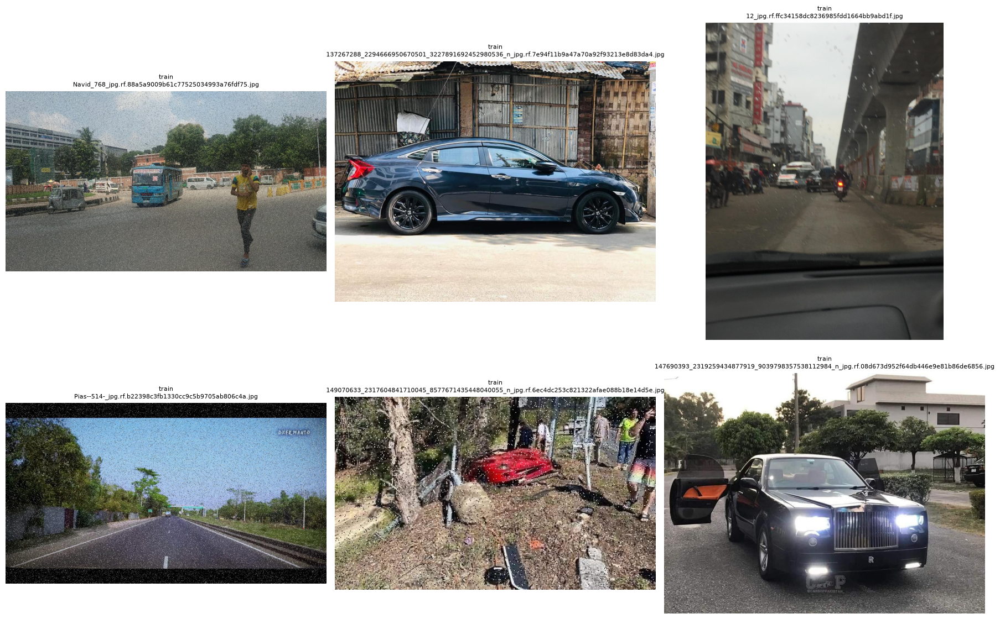

In [10]:
random.seed(42)

samples = random.sample(no_object_xml, 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for ax, (split, xml_name) in zip(axes, samples):
    folder = localization_root / split
    stem = Path(xml_name).stem

    image_path = None

    for ext in [".jpg", ".jpeg", ".png"]:
        candidate = folder / f"{stem}{ext}"
        if candidate.exists():
            image_path = candidate
            break

    if image_path:
        image = Image.open(image_path)
        ax.imshow(image)
        ax.set_title(
            f"{split}\n{image_path.name}",
            fontsize=8
        )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
from collections import Counter, defaultdict

def original_name(filename):
    stem = Path(filename).stem

    if ".rf." in stem:
        return stem.split(".rf.")[0]

    return stem

empty_originals = Counter()
annotated_originals = Counter()

for split in ["train", "validation", "test"]:
    folder = localization_root / split

    for xml_file in folder.glob("*.xml"):
        tree = ET.parse(xml_file)
        root = tree.getroot()

        base = original_name(xml_file.name)

        if len(root.findall("object")) == 0:
            empty_originals[base] += 1
        else:
            annotated_originals[base] += 1

both = set(empty_originals) & set(annotated_originals)

print("Unique originals with empty annotations:", len(empty_originals))
print("Unique originals with plate annotations:", len(annotated_originals))
print("Originals appearing in BOTH groups:", len(both))

print("\nExamples appearing in both:")
for name in sorted(both)[:20]:
    print(
        name,
        "| empty versions:", empty_originals[name],
        "| annotated versions:", annotated_originals[name]
    )

Unique originals with empty annotations: 764
Unique originals with plate annotations: 1960
Originals appearing in BOTH groups: 33

Examples appearing in both:
101_jpg | empty versions: 4 | annotated versions: 1
107_jpg | empty versions: 4 | annotated versions: 4
108_jpg | empty versions: 1 | annotated versions: 4
109_jpg | empty versions: 4 | annotated versions: 4
111_jpg | empty versions: 4 | annotated versions: 1
112_jpg | empty versions: 1 | annotated versions: 4
118_jpg | empty versions: 1 | annotated versions: 4
123_jpg | empty versions: 4 | annotated versions: 4
129_jpg | empty versions: 4 | annotated versions: 4
12_jpg | empty versions: 1 | annotated versions: 4
130_jpg | empty versions: 4 | annotated versions: 4
132_jpg | empty versions: 3 | annotated versions: 4
17_jpg | empty versions: 4 | annotated versions: 4
25_jpg | empty versions: 2 | annotated versions: 1
27_jpg | empty versions: 4 | annotated versions: 1
28_jpg | empty versions: 4 | annotated versions: 4
34_jpg | empty

Versions found: 8


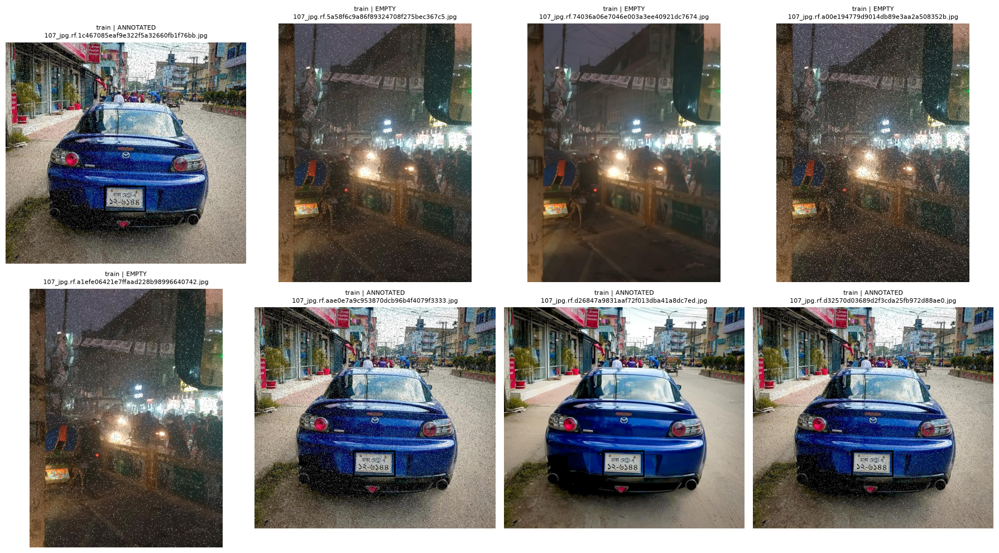

In [12]:
target_original = "107_jpg"

matching_files = []

for split in ["train", "validation", "test"]:
    folder = localization_root / split

    for xml_file in folder.glob("*.xml"):
        if original_name(xml_file.name) != target_original:
            continue

        tree = ET.parse(xml_file)
        root = tree.getroot()
        objects = root.findall("object")

        stem = xml_file.stem
        image_path = None

        for ext in [".jpg", ".jpeg", ".png"]:
            candidate = folder / f"{stem}{ext}"
            if candidate.exists():
                image_path = candidate
                break

        if image_path:
            matching_files.append(
                (split, image_path, xml_file, len(objects))
            )

print("Versions found:", len(matching_files))

cols = 4
rows = (len(matching_files) + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax in axes:
    ax.axis("off")

for ax, (split, image_path, xml_file, object_count) in zip(axes, matching_files):
    image = Image.open(image_path)

    ax.imshow(image)

    root = ET.parse(xml_file).getroot()

    for obj in root.findall("object"):
        box = obj.find("bndbox")

        xmin = int(float(box.findtext("xmin")))
        ymin = int(float(box.findtext("ymin")))
        xmax = int(float(box.findtext("xmax")))
        ymax = int(float(box.findtext("ymax")))

        rectangle = plt.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            fill=False,
            linewidth=2
        )

        ax.add_patch(rectangle)

    status = "ANNOTATED" if object_count > 0 else "EMPTY"

    ax.set_title(
        f"{split} | {status}\n{image_path.name}",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [13]:
for split in ["train", "validation", "test"]:
    folder = localization_root / split

    total = 0
    empty = 0
    annotated = 0
    objects = 0

    for xml_file in folder.glob("*.xml"):
        root = ET.parse(xml_file).getroot()
        obj = root.findall("object")

        total += 1

        if len(obj) == 0:
            empty += 1
        else:
            annotated += 1
            objects += len(obj)

    print(f"\n{split.upper()}")
    print(f"Total images      : {total}")
    print(f"Annotated images  : {annotated}")
    print(f"Empty images      : {empty}")
    print(f"Plate objects      : {objects}")
    print(f"Annotated %        : {annotated / total * 100:.2f}%")
    print(f"Empty %            : {empty / total * 100:.2f}%")


TRAIN
Total images      : 5687
Annotated images  : 4146
Empty images      : 1541
Plate objects      : 4206
Annotated %        : 72.90%
Empty %            : 27.10%

VALIDATION
Total images      : 277
Annotated images  : 185
Empty images      : 92
Plate objects      : 191
Annotated %        : 66.79%
Empty %            : 33.21%

TEST
Total images      : 553
Annotated images  : 391
Empty images      : 162
Plate objects      : 398
Annotated %        : 70.71%
Empty %            : 29.29%


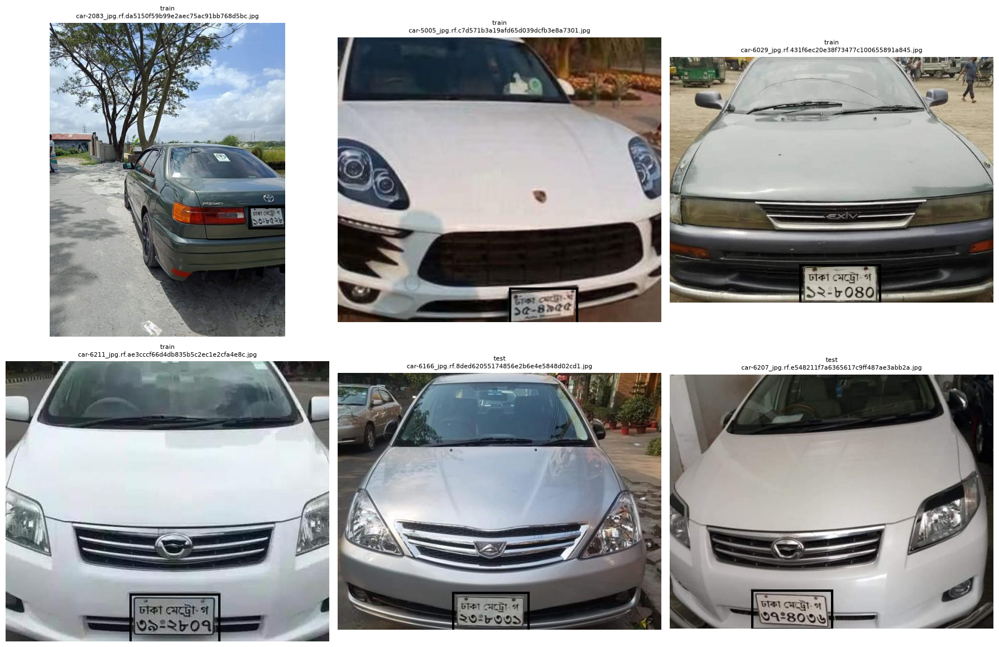

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for ax, item in zip(axes, invalid_boxes):
    split = item[0]
    xml_name = item[1]

    folder = localization_root / split
    xml_path = folder / xml_name

    root = ET.parse(xml_path).getroot()
    stem = xml_path.stem

    image_path = None

    for ext in [".jpg", ".jpeg", ".png"]:
        candidate = folder / f"{stem}{ext}"
        if candidate.exists():
            image_path = candidate
            break

    image = Image.open(image_path)
    ax.imshow(image)

    for obj in root.findall("object"):
        box = obj.find("bndbox")

        xmin = int(float(box.findtext("xmin")))
        ymin = int(float(box.findtext("ymin")))
        xmax = int(float(box.findtext("xmax")))
        ymax = int(float(box.findtext("ymax")))

        rect = plt.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            fill=False,
            linewidth=3
        )

        ax.add_patch(rect)

    ax.set_title(
        f"{split}\n{image_path.name}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
dimension_mismatches = []

for split in ["train", "validation", "test"]:
    folder = localization_root / split

    for xml_file in folder.glob("*.xml"):
        root = ET.parse(xml_file).getroot()

        size = root.find("size")
        xml_width = int(size.findtext("width"))
        xml_height = int(size.findtext("height"))

        stem = xml_file.stem
        image_path = None

        for ext in [".jpg", ".jpeg", ".png"]:
            candidate = folder / f"{stem}{ext}"
            if candidate.exists():
                image_path = candidate
                break

        if image_path is None:
            continue

        with Image.open(image_path) as img:
            actual_width, actual_height = img.size

        if (xml_width, xml_height) != (actual_width, actual_height):
            dimension_mismatches.append(
                (
                    split,
                    image_path.name,
                    (xml_width, xml_height),
                    (actual_width, actual_height)
                )
            )

print("Total dimension mismatches:", len(dimension_mismatches))

print("\nFirst 20 mismatches:")
for item in dimension_mismatches[:20]:
    print(item)

Total dimension mismatches: 218

First 20 mismatches:
('train', '151649571_266233964996756_888949322678368804_n_jpg.rf.00cada97a49866bfacc5c03852ebab60.jpg', (2048, 1536), (2047, 1535))
('train', '151649571_266233964996756_888949322678368804_n_jpg.rf.04c6212211d8d9dbdd5cf888eb6921f1.jpg', (2048, 1536), (2047, 1535))
('train', '151649571_266233964996756_888949322678368804_n_jpg.rf.10454ce39c60f9dae89c227c4a06e9f4.jpg', (2048, 1536), (2047, 1535))
('train', '151649571_266233964996756_888949322678368804_n_jpg.rf.8b8117f3eaca8d3e89de399bf85666f6.jpg', (2048, 1536), (2047, 1535))
('train', '151665421_301349461324233_4237386951681230651_n_jpg.rf.1ca9d8679dd6d8fc99cadf33da845aa1.jpg', (2048, 1536), (2047, 1535))
('train', '151665421_301349461324233_4237386951681230651_n_jpg.rf.632987bb44d1a9c6b664760b4d63e9d0.jpg', (2048, 1536), (2047, 1535))
('train', '151665421_301349461324233_4237386951681230651_n_jpg.rf.7ea139a79daaa19ebb8167b479103f21.jpg', (2048, 1536), (2047, 1535))
('train', '15166542

In [16]:
from collections import Counter

difference_counts = Counter()
mismatch_by_split = Counter()

for split, filename, xml_size, actual_size in dimension_mismatches:
    xml_w, xml_h = xml_size
    actual_w, actual_h = actual_size

    diff = (
        xml_w - actual_w,
        xml_h - actual_h
    )

    difference_counts[diff] += 1
    mismatch_by_split[split] += 1

print("DIMENSION MISMATCHES BY SPLIT")
for split in ["train", "validation", "test"]:
    print(f"{split}: {mismatch_by_split[split]}")

print("\nDIMENSION DIFFERENCE PATTERNS")
for difference, count in difference_counts.most_common():
    print(
        f"XML - Actual = {difference} : {count} images"
    )

print("\nMaximum absolute width difference:",
      max(abs(x[0]) for x in difference_counts))

print("Maximum absolute height difference:",
      max(abs(x[1]) for x in difference_counts))

DIMENSION MISMATCHES BY SPLIT
train: 194
validation: 5
test: 19

DIMENSION DIFFERENCE PATTERNS
XML - Actual = (1, 1) : 180 images
XML - Actual = (0, 2) : 15 images
XML - Actual = (0, 1) : 10 images
XML - Actual = (1, 0) : 9 images
XML - Actual = (1, 2) : 4 images

Maximum absolute width difference: 1
Maximum absolute height difference: 2


In [17]:
actual_invalid_boxes = []

for split in ["train", "validation", "test"]:
    folder = localization_root / split

    for xml_file in folder.glob("*.xml"):
        root = ET.parse(xml_file).getroot()
        stem = xml_file.stem

        image_path = None

        for ext in [".jpg", ".jpeg", ".png"]:
            candidate = folder / f"{stem}{ext}"
            if candidate.exists():
                image_path = candidate
                break

        if image_path is None:
            continue

        with Image.open(image_path) as img:
            actual_width, actual_height = img.size

        for obj in root.findall("object"):
            box = obj.find("bndbox")

            if box is None:
                continue

            xmin = int(float(box.findtext("xmin")))
            ymin = int(float(box.findtext("ymin")))
            xmax = int(float(box.findtext("xmax")))
            ymax = int(float(box.findtext("ymax")))

            if (
                xmin < 0
                or ymin < 0
                or xmax > actual_width
                or ymax > actual_height
                or xmin >= xmax
                or ymin >= ymax
            ):
                actual_invalid_boxes.append(
                    (
                        split,
                        xml_file.name,
                        (xmin, ymin, xmax, ymax),
                        (actual_width, actual_height)
                    )
                )

print("Boxes invalid against ACTUAL image dimensions:",
      len(actual_invalid_boxes))

for item in actual_invalid_boxes:
    print(item)

Boxes invalid against ACTUAL image dimensions: 6
('train', 'car-2083_jpg.rf.da5150f59b99e2aec75ac91bb768d5bc.xml', (611, 563, 721, 628), (720, 960))
('train', 'car-5005_jpg.rf.c7d571b3a19afd65d039dcfb3e8a7301.xml', (177, 258, 246, 294), (333, 293))
('train', 'car-6029_jpg.rf.431f6ec20e38f73477c100655891a845.xml', (293, 467, 471, 552), (726, 551))
('train', 'car-6211_jpg.rf.ae3cccf66d4db835b5c2ec1e2cfa4e8c.xml', (180, 336, 308, 405), (467, 404))
('test', 'car-6166_jpg.rf.8ded62055174856e2b6e4e5848d02cd1.xml', (238, 453, 393, 531), (668, 530))
('test', 'car-6207_jpg.rf.e548211f7a6365617c9ff487ae3abb2a.xml', (161, 422, 317, 497), (632, 496))


In [18]:
import shutil
import xml.etree.ElementTree as ET
from PIL import Image

source_root = DATASET_ROOT / "License Plate Localization"
cleaned_root = PROJECT_ROOT / "dataset" / "cleaned" / "License Plate Localization"

stats = {
    "images_copied": 0,
    "xml_processed": 0,
    "dimensions_fixed": 0,
    "boxes_clipped": 0
}

for split in ["train", "validation", "test"]:
    source_folder = source_root / split
    target_folder = cleaned_root / split

    target_folder.mkdir(parents=True, exist_ok=True)

    for image_path in source_folder.iterdir():
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            shutil.copy2(image_path, target_folder / image_path.name)
            stats["images_copied"] += 1

    for xml_path in source_folder.glob("*.xml"):
        tree = ET.parse(xml_path)
        root = tree.getroot()

        stem = xml_path.stem
        image_path = None

        for ext in [".jpg", ".jpeg", ".png"]:
            candidate = source_folder / f"{stem}{ext}"
            if candidate.exists():
                image_path = candidate
                break

        if image_path is None:
            print("WARNING: Image not found for:", xml_path.name)
            continue

        with Image.open(image_path) as img:
            actual_width, actual_height = img.size

        size = root.find("size")

        old_width = int(size.findtext("width"))
        old_height = int(size.findtext("height"))

        if old_width != actual_width or old_height != actual_height:
            size.find("width").text = str(actual_width)
            size.find("height").text = str(actual_height)
            stats["dimensions_fixed"] += 1

        for obj in root.findall("object"):
            box = obj.find("bndbox")

            if box is None:
                continue

            xmin = int(float(box.findtext("xmin")))
            ymin = int(float(box.findtext("ymin")))
            xmax = int(float(box.findtext("xmax")))
            ymax = int(float(box.findtext("ymax")))

            new_xmin = max(0, min(xmin, actual_width))
            new_ymin = max(0, min(ymin, actual_height))
            new_xmax = max(0, min(xmax, actual_width))
            new_ymax = max(0, min(ymax, actual_height))

            if (xmin, ymin, xmax, ymax) != (
                new_xmin,
                new_ymin,
                new_xmax,
                new_ymax
            ):
                box.find("xmin").text = str(new_xmin)
                box.find("ymin").text = str(new_ymin)
                box.find("xmax").text = str(new_xmax)
                box.find("ymax").text = str(new_ymax)

                stats["boxes_clipped"] += 1

        output_xml = target_folder / xml_path.name

        tree.write(
            output_xml,
            encoding="utf-8",
            xml_declaration=True
        )

        stats["xml_processed"] += 1

print("CLEANED DATASET CREATED")
print("-----------------------")

for key, value in stats.items():
    print(f"{key}: {value}")

print("\nLocation:")
print(cleaned_root)

CLEANED DATASET CREATED
-----------------------
images_copied: 6517
xml_processed: 6517
dimensions_fixed: 218
boxes_clipped: 6

Location:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\cleaned\License Plate Localization


In [19]:
cleaned_localization_root = (
    PROJECT_ROOT
    / "dataset"
    / "cleaned"
    / "License Plate Localization"
)

cleaned_dimension_mismatches = []
cleaned_invalid_boxes = []
cleaned_missing_pairs = []

for split in ["train", "validation", "test"]:
    folder = cleaned_localization_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    xml_files = list(folder.glob("*.xml"))

    image_stems = {f.stem for f in images}
    xml_stems = {f.stem for f in xml_files}

    if image_stems != xml_stems:
        cleaned_missing_pairs.append(split)

    for xml_file in xml_files:
        root = ET.parse(xml_file).getroot()

        image_path = None

        for ext in [".jpg", ".jpeg", ".png"]:
            candidate = folder / f"{xml_file.stem}{ext}"
            if candidate.exists():
                image_path = candidate
                break

        if image_path is None:
            continue

        with Image.open(image_path) as img:
            actual_width, actual_height = img.size

        size = root.find("size")

        xml_width = int(size.findtext("width"))
        xml_height = int(size.findtext("height"))

        if (xml_width, xml_height) != (actual_width, actual_height):
            cleaned_dimension_mismatches.append(
                (
                    split,
                    xml_file.name,
                    (xml_width, xml_height),
                    (actual_width, actual_height)
                )
            )

        for obj in root.findall("object"):
            box = obj.find("bndbox")

            if box is None:
                continue

            xmin = int(float(box.findtext("xmin")))
            ymin = int(float(box.findtext("ymin")))
            xmax = int(float(box.findtext("xmax")))
            ymax = int(float(box.findtext("ymax")))

            if (
                xmin < 0
                or ymin < 0
                or xmax > actual_width
                or ymax > actual_height
                or xmin >= xmax
                or ymin >= ymax
            ):
                cleaned_invalid_boxes.append(
                    (
                        split,
                        xml_file.name,
                        (xmin, ymin, xmax, ymax)
                    )
                )

print("CLEANED DATASET VERIFICATION")
print("----------------------------")
print("Missing image/XML pair splits:",
      len(cleaned_missing_pairs))
print("Dimension mismatches:",
      len(cleaned_dimension_mismatches))
print("Invalid bounding boxes:",
      len(cleaned_invalid_boxes))

print("\nFILES BY SPLIT")

for split in ["train", "validation", "test"]:
    folder = cleaned_localization_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    xml_files = list(folder.glob("*.xml"))

    print(
        f"{split}: {len(images)} images, "
        f"{len(xml_files)} XML"
    )

CLEANED DATASET VERIFICATION
----------------------------
Missing image/XML pair splits: 0
Dimension mismatches: 0
Invalid bounding boxes: 0

FILES BY SPLIT
train: 5687 images, 5687 XML
validation: 277 images, 277 XML
test: 553 images, 553 XML


In [20]:
character_root = DATASET_ROOT / "Character Recognition"

for split in ["train", "validation", "test"]:
    folder = character_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    xml_files = list(folder.glob("*.xml"))

    print(f"{split.upper()}")
    print(f"Images : {len(images)}")
    print(f"XML    : {len(xml_files)}")
    print()

TRAIN
Images : 3480
XML    : 3480

VALIDATION
Images : 363
XML    : 363

TEST
Images : 218
XML    : 218



In [21]:
for split in ["train", "validation", "test"]:
    folder = character_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    xml_files = list(folder.glob("*.xml"))

    image_stems = {file.stem for file in images}
    xml_stems = {file.stem for file in xml_files}

    images_without_xml = image_stems - xml_stems
    xml_without_images = xml_stems - image_stems

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("XML files:", len(xml_files))
    print("Images without XML:", len(images_without_xml))
    print("XML without image:", len(xml_without_images))


--- TRAIN ---
Images: 3480
XML files: 3480
Images without XML: 0
XML without image: 0

--- VALIDATION ---
Images: 363
XML files: 363
Images without XML: 0
XML without image: 0

--- TEST ---
Images: 218
XML files: 218
Images without XML: 0
XML without image: 0


In [22]:
from collections import Counter
import xml.etree.ElementTree as ET

char_total_xml = 0
char_valid_xml = 0
char_corrupt_xml = []
char_no_object_xml = []
char_invalid_boxes = []
char_class_counts = Counter()

for split in ["train", "validation", "test"]:
    folder = character_root / split

    for xml_file in folder.glob("*.xml"):
        char_total_xml += 1

        try:
            tree = ET.parse(xml_file)
            root = tree.getroot()

            size = root.find("size")

            if size is None:
                char_corrupt_xml.append(
                    (split, xml_file.name, "Missing size")
                )
                continue

            width = int(size.findtext("width", 0))
            height = int(size.findtext("height", 0))

            objects = root.findall("object")

            if len(objects) == 0:
                char_no_object_xml.append(
                    (split, xml_file.name)
                )

            for obj in objects:
                class_name = obj.findtext("name", "UNKNOWN")

                char_class_counts[class_name] += 1

                box = obj.find("bndbox")

                if box is None:
                    char_invalid_boxes.append(
                        (
                            split,
                            xml_file.name,
                            class_name,
                            "Missing bndbox"
                        )
                    )
                    continue

                xmin = int(float(box.findtext("xmin", 0)))
                ymin = int(float(box.findtext("ymin", 0)))
                xmax = int(float(box.findtext("xmax", 0)))
                ymax = int(float(box.findtext("ymax", 0)))

                if (
                    xmin < 0
                    or ymin < 0
                    or xmax > width
                    or ymax > height
                    or xmin >= xmax
                    or ymin >= ymax
                ):
                    char_invalid_boxes.append(
                        (
                            split,
                            xml_file.name,
                            class_name,
                            (xmin, ymin, xmax, ymax),
                            (width, height)
                        )
                    )

            char_valid_xml += 1

        except Exception as e:
            char_corrupt_xml.append(
                (split, xml_file.name, str(e))
            )

print("CHARACTER RECOGNITION AUDIT")
print("---------------------------")
print("Total XML files:", char_total_xml)
print("Successfully parsed:", char_valid_xml)
print("Corrupt/problem XML:", len(char_corrupt_xml))
print("XML with no objects:", len(char_no_object_xml))
print("Invalid bounding boxes:", len(char_invalid_boxes))

print("\nTotal character objects:",
      sum(char_class_counts.values()))

print("Number of classes:",
      len(char_class_counts))

print("\nCLASS DISTRIBUTION")
for class_name, count in char_class_counts.most_common():
    print(f"{class_name}: {count}")

CHARACTER RECOGNITION AUDIT
---------------------------
Total XML files: 4061
Successfully parsed: 4061
Corrupt/problem XML: 0
XML with no objects: 0
Invalid bounding boxes: 28

Total character objects: 35705
Number of classes: 27

CLASS DISTRIBUTION
1: 5304
metro: 3722
dhaka: 3239
0: 2861
2: 2598
3: 2462
5: 2188
4: 2080
ga: 1860
9: 1781
7: 1765
8: 1639
6: 1577
ta: 389
khulna: 387
ba: 354
ja: 317
gha: 289
kha: 187
jashore: 174
chattogram: 130
ha: 112
ca: 94
da: 57
ka: 53
va: 46
na: 40


In [23]:
char_dimension_mismatches = []
char_actual_invalid_boxes = []

for split in ["train", "validation", "test"]:
    folder = character_root / split

    for xml_file in folder.glob("*.xml"):
        root = ET.parse(xml_file).getroot()

        stem = xml_file.stem
        image_path = None

        for ext in [".jpg", ".jpeg", ".png"]:
            candidate = folder / f"{stem}{ext}"
            if candidate.exists():
                image_path = candidate
                break

        if image_path is None:
            continue

        with Image.open(image_path) as img:
            actual_width, actual_height = img.size

        size = root.find("size")

        xml_width = int(size.findtext("width"))
        xml_height = int(size.findtext("height"))

        if (xml_width, xml_height) != (actual_width, actual_height):
            char_dimension_mismatches.append(
                (
                    split,
                    image_path.name,
                    (xml_width, xml_height),
                    (actual_width, actual_height)
                )
            )

        for obj in root.findall("object"):
            box = obj.find("bndbox")

            if box is None:
                continue

            class_name = obj.findtext("name", "UNKNOWN")

            xmin = int(float(box.findtext("xmin")))
            ymin = int(float(box.findtext("ymin")))
            xmax = int(float(box.findtext("xmax")))
            ymax = int(float(box.findtext("ymax")))

            if (
                xmin < 0
                or ymin < 0
                or xmax > actual_width
                or ymax > actual_height
                or xmin >= xmax
                or ymin >= ymax
            ):
                char_actual_invalid_boxes.append(
                    (
                        split,
                        xml_file.name,
                        class_name,
                        (xmin, ymin, xmax, ymax),
                        (actual_width, actual_height)
                    )
                )

print("CHARACTER DATASET - ACTUAL IMAGE CHECK")
print("--------------------------------------")
print("Dimension mismatches:",
      len(char_dimension_mismatches))

print("Bounding boxes invalid against actual images:",
      len(char_actual_invalid_boxes))

print("\nFirst 10 dimension mismatches:")
for item in char_dimension_mismatches[:10]:
    print(item)

print("\nFirst 20 invalid boxes:")
for item in char_actual_invalid_boxes[:20]:
    print(item)

CHARACTER DATASET - ACTUAL IMAGE CHECK
--------------------------------------
Dimension mismatches: 0
Bounding boxes invalid against actual images: 28

First 10 dimension mismatches:

First 20 invalid boxes:
('train', '24_314_1_jpg.rf.86524d733e31f1e37cec562a9bd72da4.xml', '1', (272, 115, 321, 189), (416, 188))
('train', 'car-1001_989_1_jpg.rf.4742e9e7a0e2993e86d38682cb157627.xml', '5', (320, 151, 373, 231), (416, 230))
('train', 'car-1039_1184_1_jpg.rf.4f16762459ea3d0469abce470f460ded.xml', '8', (357, 251, 417, 380), (416, 395))
('train', 'car-1094_741_1_jpg.rf.7da4414dc72725601278c93a4b48fa92.xml', '4', (334, 214, 400, 347), (416, 346))
('train', 'car-2028_419_1_jpg.rf.00d44299590de7582cb399399941c6b1.xml', '3', (30, 122, 87, 208), (416, 207))
('train', 'car-2028_419_1_jpg.rf.00d44299590de7582cb399399941c6b1.xml', '7', (87, 125, 142, 208), (416, 207))
('train', 'car-2028_419_1_jpg.rf.00d44299590de7582cb399399941c6b1.xml', '8', (176, 120, 234, 208), (416, 207))
('train', 'car-2028_419

In [24]:
from collections import Counter

char_box_errors = Counter()
char_invalid_by_split = Counter()

for item in char_actual_invalid_boxes:
    split, xml_name, class_name, box, image_size = item

    xmin, ymin, xmax, ymax = box
    width, height = image_size

    left_error = max(0, -xmin)
    top_error = max(0, -ymin)
    right_error = max(0, xmax - width)
    bottom_error = max(0, ymax - height)

    error = (
        left_error,
        top_error,
        right_error,
        bottom_error
    )

    char_box_errors[error] += 1
    char_invalid_by_split[split] += 1

print("INVALID BOXES BY SPLIT")
for split in ["train", "validation", "test"]:
    print(f"{split}: {char_invalid_by_split[split]}")

print("\nBOUNDARY ERROR PATTERNS")
for error, count in char_box_errors.most_common():
    print(f"{error}: {count} boxes")

print("\nMaximum boundary exceedance:")
print(
    max(
        max(error)
        for error in char_box_errors
    ),
    "pixel(s)"
)

INVALID BOXES BY SPLIT
train: 17
validation: 6
test: 5

BOUNDARY ERROR PATTERNS
(0, 0, 0, 1): 16 boxes
(0, 0, 1, 0): 12 boxes

Maximum boundary exceedance:
1 pixel(s)


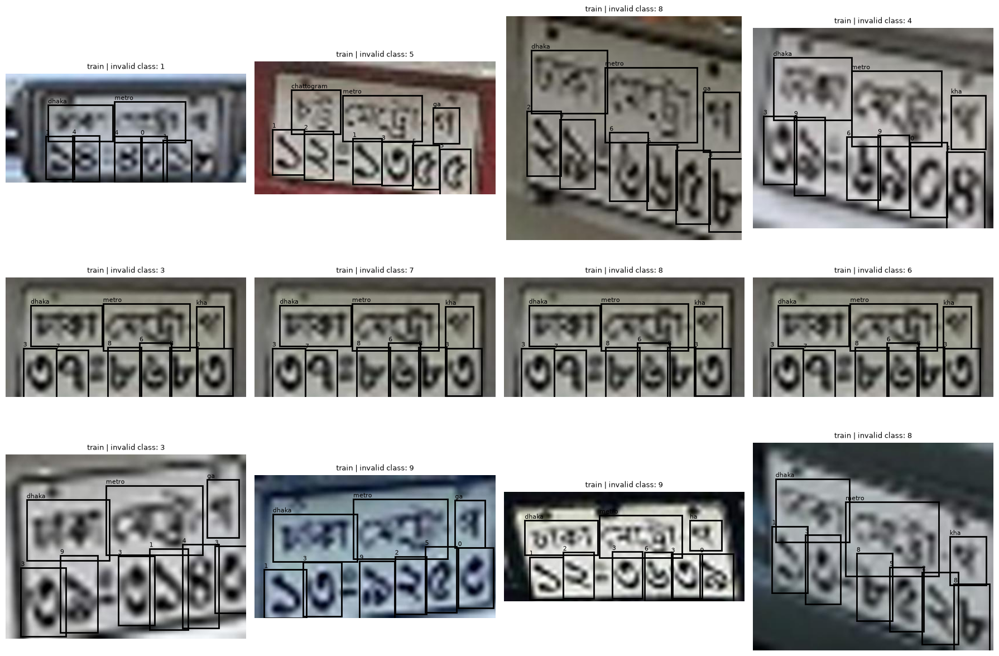

In [25]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for ax, item in zip(axes, char_actual_invalid_boxes[:12]):
    split, xml_name, class_name, box, image_size = item

    folder = character_root / split
    xml_path = folder / xml_name

    stem = xml_path.stem
    image_path = None

    for ext in [".jpg", ".jpeg", ".png"]:
        candidate = folder / f"{stem}{ext}"
        if candidate.exists():
            image_path = candidate
            break

    image = Image.open(image_path)
    ax.imshow(image)

    root = ET.parse(xml_path).getroot()

    for obj in root.findall("object"):
        bbox = obj.find("bndbox")

        xmin = int(float(bbox.findtext("xmin")))
        ymin = int(float(bbox.findtext("ymin")))
        xmax = int(float(bbox.findtext("xmax")))
        ymax = int(float(bbox.findtext("ymax")))

        label = obj.findtext("name", "UNKNOWN")

        rect = plt.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            fill=False,
            linewidth=2
        )

        ax.add_patch(rect)

        ax.text(
            xmin,
            max(0, ymin - 3),
            label,
            fontsize=8
        )

    ax.set_title(
        f"{split} | invalid class: {class_name}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [26]:
cleaned_character_root = (
    PROJECT_ROOT
    / "dataset"
    / "cleaned"
    / "Character Recognition"
)

char_clean_stats = {
    "images_copied": 0,
    "xml_processed": 0,
    "boxes_clipped": 0
}

for split in ["train", "validation", "test"]:
    source_folder = character_root / split
    target_folder = cleaned_character_root / split

    target_folder.mkdir(parents=True, exist_ok=True)

    # Copy images
    for image_path in source_folder.iterdir():
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            shutil.copy2(
                image_path,
                target_folder / image_path.name
            )
            char_clean_stats["images_copied"] += 1

    # Process XML files
    for xml_path in source_folder.glob("*.xml"):
        tree = ET.parse(xml_path)
        root = tree.getroot()

        stem = xml_path.stem
        image_path = None

        for ext in [".jpg", ".jpeg", ".png"]:
            candidate = source_folder / f"{stem}{ext}"

            if candidate.exists():
                image_path = candidate
                break

        if image_path is None:
            print("WARNING: Image not found:", xml_path.name)
            continue

        with Image.open(image_path) as img:
            width, height = img.size

        for obj in root.findall("object"):
            box = obj.find("bndbox")

            if box is None:
                continue

            xmin = int(float(box.findtext("xmin")))
            ymin = int(float(box.findtext("ymin")))
            xmax = int(float(box.findtext("xmax")))
            ymax = int(float(box.findtext("ymax")))

            new_xmin = max(0, min(xmin, width))
            new_ymin = max(0, min(ymin, height))
            new_xmax = max(0, min(xmax, width))
            new_ymax = max(0, min(ymax, height))

            old_box = (xmin, ymin, xmax, ymax)
            new_box = (
                new_xmin,
                new_ymin,
                new_xmax,
                new_ymax
            )

            if old_box != new_box:
                box.find("xmin").text = str(new_xmin)
                box.find("ymin").text = str(new_ymin)
                box.find("xmax").text = str(new_xmax)
                box.find("ymax").text = str(new_ymax)

                char_clean_stats["boxes_clipped"] += 1

        output_xml = target_folder / xml_path.name

        tree.write(
            output_xml,
            encoding="utf-8",
            xml_declaration=True
        )

        char_clean_stats["xml_processed"] += 1

print("CLEANED CHARACTER DATASET CREATED")
print("---------------------------------")

for key, value in char_clean_stats.items():
    print(f"{key}: {value}")

print("\nLocation:")
print(cleaned_character_root)

CLEANED CHARACTER DATASET CREATED
---------------------------------
images_copied: 4061
xml_processed: 4061
boxes_clipped: 28

Location:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\cleaned\Character Recognition


In [27]:
clean_char_dimension_mismatches = []
clean_char_invalid_boxes = []
clean_char_missing_images = []
clean_char_missing_xml = []

for split in ["train", "validation", "test"]:
    folder = cleaned_character_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    xml_files = list(folder.glob("*.xml"))

    image_stems = {f.stem for f in images}
    xml_stems = {f.stem for f in xml_files}

    for stem in image_stems - xml_stems:
        clean_char_missing_xml.append((split, stem))

    for stem in xml_stems - image_stems:
        clean_char_missing_images.append((split, stem))

    for xml_file in xml_files:
        root = ET.parse(xml_file).getroot()

        image_path = None

        for ext in [".jpg", ".jpeg", ".png"]:
            candidate = folder / f"{xml_file.stem}{ext}"

            if candidate.exists():
                image_path = candidate
                break

        if image_path is None:
            continue

        with Image.open(image_path) as img:
            actual_width, actual_height = img.size

        size = root.find("size")

        xml_width = int(size.findtext("width"))
        xml_height = int(size.findtext("height"))

        if (xml_width, xml_height) != (actual_width, actual_height):
            clean_char_dimension_mismatches.append(
                (
                    split,
                    xml_file.name,
                    (xml_width, xml_height),
                    (actual_width, actual_height)
                )
            )

        for obj in root.findall("object"):
            box = obj.find("bndbox")

            if box is None:
                continue

            xmin = int(float(box.findtext("xmin")))
            ymin = int(float(box.findtext("ymin")))
            xmax = int(float(box.findtext("xmax")))
            ymax = int(float(box.findtext("ymax")))

            if (
                xmin < 0
                or ymin < 0
                or xmax > actual_width
                or ymax > actual_height
                or xmin >= xmax
                or ymin >= ymax
            ):
                clean_char_invalid_boxes.append(
                    (
                        split,
                        xml_file.name,
                        obj.findtext("name"),
                        (xmin, ymin, xmax, ymax),
                        (actual_width, actual_height)
                    )
                )

print("CLEANED CHARACTER DATASET VERIFICATION")
print("--------------------------------------")

print("Images without XML:",
      len(clean_char_missing_xml))

print("XML without image:",
      len(clean_char_missing_images))

print("Dimension mismatches:",
      len(clean_char_dimension_mismatches))

print("Invalid bounding boxes:",
      len(clean_char_invalid_boxes))

print("\nFILES BY SPLIT")

for split in ["train", "validation", "test"]:
    folder = cleaned_character_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    xml_files = list(folder.glob("*.xml"))

    print(
        f"{split}: {len(images)} images, "
        f"{len(xml_files)} XML"
    )

CLEANED CHARACTER DATASET VERIFICATION
--------------------------------------
Images without XML: 0
XML without image: 0
Dimension mismatches: 0
Invalid bounding boxes: 0

FILES BY SPLIT
train: 3480 images, 3480 XML
validation: 363 images, 363 XML
test: 218 images, 218 XML


In [28]:
import hashlib
from collections import defaultdict

def file_md5(path):
    hasher = hashlib.md5()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            hasher.update(chunk)

    return hasher.hexdigest()


def find_exact_cross_split_duplicates(root):
    hash_records = defaultdict(list)

    for split in ["train", "validation", "test"]:
        folder = root / split

        images = (
            list(folder.glob("*.jpg"))
            + list(folder.glob("*.jpeg"))
            + list(folder.glob("*.png"))
        )

        for image_path in images:
            image_hash = file_md5(image_path)

            hash_records[image_hash].append(
                (split, image_path.name)
            )

    cross_split = {}

    for image_hash, records in hash_records.items():
        splits = {record[0] for record in records}

        if len(splits) > 1:
            cross_split[image_hash] = records

    return cross_split


localization_exact_duplicates = (
    find_exact_cross_split_duplicates(
        cleaned_localization_root
    )
)

print("LOCALIZATION EXACT CROSS-SPLIT DUPLICATES")
print("-----------------------------------------")
print(
    "Duplicate groups:",
    len(localization_exact_duplicates)
)

duplicate_files = sum(
    len(records)
    for records in localization_exact_duplicates.values()
)

print("Files involved:", duplicate_files)

print("\nFirst 10 duplicate groups:")

for i, records in enumerate(
    localization_exact_duplicates.values()
):
    if i >= 10:
        break

    print(f"\nGroup {i + 1}")

    for split, filename in records:
        print(f"  {split}: {filename}")

LOCALIZATION EXACT CROSS-SPLIT DUPLICATES
-----------------------------------------
Duplicate groups: 33
Files involved: 68

First 10 duplicate groups:

Group 1
  train: car-2031_jpg.rf.3b8c8823b831b634f134e8fef52363fb.jpg
  test: car-2027_jpg.rf.db1aeccacf5a19a735a685e9021276fa.jpg

Group 2
  train: car-3216_jpg.rf.773d3a4ac96d129e883a2f1d21c719a9.jpg
  test: car-3321_jpg.rf.13e6dc7f55674b4a7d811a7ee243c017.jpg

Group 3
  train: car-6095_jpg.rf.6d874d5c9bbb0ea1828f7e9bf58674bf.jpg
  test: car-6334_jpg.rf.e951c06bdfef6c4bf94d31397b5c8699.jpg

Group 4
  train: car-6133_jpg.rf.bfe434377d043f8dd931ef4cdbd2454b.jpg
  test: car-6365_jpg.rf.7e89a92a3ab517865ec89bd3ae4e7df0.jpg

Group 5
  train: car-6138_jpg.rf.244adbca41bd74174498fc8ea459a15e.jpg
  train: car-6138_jpg.rf.604b3afb2cd71dbb284ef191efa179ff.jpg
  test: car-6346_jpg.rf.517e571af1cedbc04048d5c110e70c88.jpg

Group 6
  train: car-6283_jpg.rf.29bfa816d864554b2331dc3ff5b880ab.jpg
  test: car-6357_jpg.rf.20a9226f881922cc71d4a52273b3720

In [29]:
from collections import Counter

split_pair_counts = Counter()

for records in localization_exact_duplicates.values():
    splits = sorted(set(split for split, _ in records))

    pair = " <-> ".join(splits)
    split_pair_counts[pair] += 1

print("LOCALIZATION EXACT DUPLICATE LEAKAGE")
print("------------------------------------")

for pair, count in split_pair_counts.items():
    print(f"{pair}: {count} duplicate groups")

print("\nALL DUPLICATE GROUPS")

for i, records in enumerate(
    localization_exact_duplicates.values(),
    start=1
):
    print(f"\nGroup {i}")

    for split, filename in records:
        print(f"  {split}: {filename}")

LOCALIZATION EXACT DUPLICATE LEAKAGE
------------------------------------
test <-> train: 11 duplicate groups
train <-> validation: 19 duplicate groups
test <-> validation: 3 duplicate groups

ALL DUPLICATE GROUPS

Group 1
  train: car-2031_jpg.rf.3b8c8823b831b634f134e8fef52363fb.jpg
  test: car-2027_jpg.rf.db1aeccacf5a19a735a685e9021276fa.jpg

Group 2
  train: car-3216_jpg.rf.773d3a4ac96d129e883a2f1d21c719a9.jpg
  test: car-3321_jpg.rf.13e6dc7f55674b4a7d811a7ee243c017.jpg

Group 3
  train: car-6095_jpg.rf.6d874d5c9bbb0ea1828f7e9bf58674bf.jpg
  test: car-6334_jpg.rf.e951c06bdfef6c4bf94d31397b5c8699.jpg

Group 4
  train: car-6133_jpg.rf.bfe434377d043f8dd931ef4cdbd2454b.jpg
  test: car-6365_jpg.rf.7e89a92a3ab517865ec89bd3ae4e7df0.jpg

Group 5
  train: car-6138_jpg.rf.244adbca41bd74174498fc8ea459a15e.jpg
  train: car-6138_jpg.rf.604b3afb2cd71dbb284ef191efa179ff.jpg
  test: car-6346_jpg.rf.517e571af1cedbc04048d5c110e70c88.jpg

Group 6
  train: car-6283_jpg.rf.29bfa816d864554b2331dc3ff5b880

In [30]:
from collections import Counter

split_pair_counts = Counter()

for records in localization_exact_duplicates.values():
    splits = sorted(set(split for split, _ in records))

    pair = " <-> ".join(splits)
    split_pair_counts[pair] += 1

print("LOCALIZATION EXACT DUPLICATE LEAKAGE")
print("------------------------------------")

for pair, count in split_pair_counts.items():
    print(f"{pair}: {count} duplicate groups")

print("\nALL DUPLICATE GROUPS")

for i, records in enumerate(
    localization_exact_duplicates.values(),
    start=1
):
    print(f"\nGroup {i}")

    for split, filename in records:
        print(f"  {split}: {filename}")

LOCALIZATION EXACT DUPLICATE LEAKAGE
------------------------------------
test <-> train: 11 duplicate groups
train <-> validation: 19 duplicate groups
test <-> validation: 3 duplicate groups

ALL DUPLICATE GROUPS

Group 1
  train: car-2031_jpg.rf.3b8c8823b831b634f134e8fef52363fb.jpg
  test: car-2027_jpg.rf.db1aeccacf5a19a735a685e9021276fa.jpg

Group 2
  train: car-3216_jpg.rf.773d3a4ac96d129e883a2f1d21c719a9.jpg
  test: car-3321_jpg.rf.13e6dc7f55674b4a7d811a7ee243c017.jpg

Group 3
  train: car-6095_jpg.rf.6d874d5c9bbb0ea1828f7e9bf58674bf.jpg
  test: car-6334_jpg.rf.e951c06bdfef6c4bf94d31397b5c8699.jpg

Group 4
  train: car-6133_jpg.rf.bfe434377d043f8dd931ef4cdbd2454b.jpg
  test: car-6365_jpg.rf.7e89a92a3ab517865ec89bd3ae4e7df0.jpg

Group 5
  train: car-6138_jpg.rf.244adbca41bd74174498fc8ea459a15e.jpg
  train: car-6138_jpg.rf.604b3afb2cd71dbb284ef191efa179ff.jpg
  test: car-6346_jpg.rf.517e571af1cedbc04048d5c110e70c88.jpg

Group 6
  train: car-6283_jpg.rf.29bfa816d864554b2331dc3ff5b880

In [31]:
import re
from collections import defaultdict, Counter

def roboflow_source_name(filename):
    stem = Path(filename).stem

    return re.sub(
        r"\.rf\.[a-fA-F0-9]+$",
        "",
        stem
    )


source_records = defaultdict(list)

for split in ["train", "validation", "test"]:
    folder = cleaned_localization_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    for image_path in images:
        source = roboflow_source_name(image_path.name)

        source_records[source].append(
            (split, image_path.name)
        )


cross_split_sources = {}

for source, records in source_records.items():
    splits = {split for split, _ in records}

    if len(splits) > 1:
        cross_split_sources[source] = records


print("SOURCE-NAME CROSS-SPLIT LEAKAGE")
print("--------------------------------")
print(
    "Source names appearing across splits:",
    len(cross_split_sources)
)

files_involved = sum(
    len(records)
    for records in cross_split_sources.values()
)

print("Files involved:", files_involved)


pair_counts = Counter()

for records in cross_split_sources.values():
    splits = sorted(set(split for split, _ in records))

    pair = " <-> ".join(splits)
    pair_counts[pair] += 1


print("\nSPLIT COMBINATIONS")

for pair, count in pair_counts.items():
    print(f"{pair}: {count} source groups")


print("\nFIRST 20 SOURCE GROUPS")

for i, (source, records) in enumerate(
    cross_split_sources.items()
):
    if i >= 20:
        break

    print(f"\nSource: {source}")

    for split, filename in records:
        print(f"  {split}: {filename}")

SOURCE-NAME CROSS-SPLIT LEAKAGE
--------------------------------
Source names appearing across splits: 102
Files involved: 426

SPLIT COMBINATIONS
test <-> train: 61 source groups
train <-> validation: 38 source groups
test <-> train <-> validation: 1 source groups
test <-> validation: 2 source groups

FIRST 20 SOURCE GROUPS

Source: 108_jpg
  train: 108_jpg.rf.235abced1e87cdd702cd91ccaaa691a5.jpg
  train: 108_jpg.rf.29e1f7dce6e4d5225b19d17b875dff3a.jpg
  train: 108_jpg.rf.754b215d4f746efe5383ddf17bfbd63b.jpg
  train: 108_jpg.rf.96940b25fa96927da6bf47a0ae347774.jpg
  test: 108_jpg.rf.1d6040c364e7e37d586b6db5677ed4ba.jpg

Source: 112_jpg
  train: 112_jpg.rf.090ac5021f46863e9a8ec58dacb933b5.jpg
  train: 112_jpg.rf.5e8f4b0327877a723734e7cbe07c1aa4.jpg
  train: 112_jpg.rf.b46089e19fcfab49d03f08e335fc3c95.jpg
  train: 112_jpg.rf.f846b52afc31fe5cdfe66b16dfcc6b48.jpg
  test: 112_jpg.rf.c7d7491c484d704d318c24ea2e05a57e.jpg

Source: 118_jpg
  train: 118_jpg.rf.00e4d9008e53667e6e3969f42c902be4.j

In [32]:
print("CHARACTER RECOGNITION LEAKAGE CHECK")
print("===================================")

char_exact_duplicates = find_exact_cross_split_duplicates(
    cleaned_character_root
)

print("\n1. EXACT IMAGE DUPLICATES")
print("-------------------------")
print("Duplicate groups:", len(char_exact_duplicates))

exact_files = sum(
    len(records)
    for records in char_exact_duplicates.values()
)

print("Files involved:", exact_files)

char_exact_pairs = Counter()

for records in char_exact_duplicates.values():
    splits = sorted(set(split for split, _ in records))
    pair = " <-> ".join(splits)
    char_exact_pairs[pair] += 1

for pair, count in char_exact_pairs.items():
    print(f"{pair}: {count} groups")


char_source_records = defaultdict(list)

for split in ["train", "validation", "test"]:
    folder = cleaned_character_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    for image_path in images:
        source = roboflow_source_name(image_path.name)

        char_source_records[source].append(
            (split, image_path.name)
        )


char_cross_split_sources = {}

for source, records in char_source_records.items():
    splits = {split for split, _ in records}

    if len(splits) > 1:
        char_cross_split_sources[source] = records


print("\n2. SOURCE-NAME LEAKAGE")
print("----------------------")

print(
    "Source names appearing across splits:",
    len(char_cross_split_sources)
)

source_files = sum(
    len(records)
    for records in char_cross_split_sources.values()
)

print("Files involved:", source_files)

char_source_pairs = Counter()

for records in char_cross_split_sources.values():
    splits = sorted(set(split for split, _ in records))
    pair = " <-> ".join(splits)
    char_source_pairs[pair] += 1

for pair, count in char_source_pairs.items():
    print(f"{pair}: {count} source groups")


print("\nFIRST 10 LEAKING SOURCE GROUPS")

for i, (source, records) in enumerate(
    char_cross_split_sources.items()
):
    if i >= 10:
        break

    print(f"\nSource: {source}")

    for split, filename in records:
        print(f"  {split}: {filename}")

CHARACTER RECOGNITION LEAKAGE CHECK

1. EXACT IMAGE DUPLICATES
-------------------------
Duplicate groups: 0
Files involved: 0

2. SOURCE-NAME LEAKAGE
----------------------
Source names appearing across splits: 0
Files involved: 0

FIRST 10 LEAKING SOURCE GROUPS


In [33]:
all_localization_hashes = defaultdict(list)

for split in ["train", "validation", "test"]:
    folder = cleaned_localization_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    for image_path in images:
        image_hash = file_md5(image_path)

        all_localization_hashes[image_hash].append(
            (split, image_path.name)
        )


total_files = sum(
    len(records)
    for records in all_localization_hashes.values()
)

unique_hashes = len(all_localization_hashes)

duplicate_extra_files = total_files - unique_hashes


print("LOCALIZATION DUPLICATE SUMMARY")
print("==============================")

print("Total image files:", total_files)
print("Unique image contents:", unique_hashes)
print("Extra exact duplicate files:", duplicate_extra_files)


duplicate_group_sizes = Counter(
    len(records)
    for records in all_localization_hashes.values()
    if len(records) > 1
)

print("\nDUPLICATE GROUP SIZES")

if duplicate_group_sizes:
    for size, count in sorted(duplicate_group_sizes.items()):
        print(
            f"{size} identical copies: "
            f"{count} groups"
        )
else:
    print("No exact duplicates found.")


within_split_groups = 0
cross_split_groups = 0

for records in all_localization_hashes.values():

    if len(records) <= 1:
        continue

    splits = {split for split, _ in records}

    if len(splits) == 1:
        within_split_groups += 1
    else:
        cross_split_groups += 1


print("\nDUPLICATE LOCATION")

print(
    "Duplicate groups within one split:",
    within_split_groups
)

print(
    "Duplicate groups crossing splits:",
    cross_split_groups
)

LOCALIZATION DUPLICATE SUMMARY
Total image files: 6517
Unique image contents: 6405
Extra exact duplicate files: 112

DUPLICATE GROUP SIZES
2 identical copies: 108 groups
3 identical copies: 2 groups

DUPLICATE LOCATION
Duplicate groups within one split: 77
Duplicate groups crossing splits: 33


In [34]:
def annotation_signature(xml_path):
    root = ET.parse(xml_path).getroot()

    objects = []

    for obj in root.findall("object"):
        class_name = obj.findtext("name")

        box = obj.find("bndbox")

        if box is None:
            continue

        xmin = int(float(box.findtext("xmin")))
        ymin = int(float(box.findtext("ymin")))
        xmax = int(float(box.findtext("xmax")))
        ymax = int(float(box.findtext("ymax")))

        objects.append(
            (
                class_name,
                xmin,
                ymin,
                xmax,
                ymax
            )
        )

    return tuple(sorted(objects))


consistent_groups = 0
inconsistent_groups = []


for image_hash, records in all_localization_hashes.items():

    if len(records) <= 1:
        continue

    signatures = []

    for split, filename in records:

        image_path = (
            cleaned_localization_root
            / split
            / filename
        )

        xml_path = image_path.with_suffix(".xml")

        signature = annotation_signature(xml_path)

        signatures.append(
            (
                split,
                filename,
                signature
            )
        )

    unique_signatures = {
        record[2]
        for record in signatures
    }

    if len(unique_signatures) == 1:
        consistent_groups += 1
    else:
        inconsistent_groups.append(
            signatures
        )


print("EXACT DUPLICATE ANNOTATION CHECK")
print("================================")

print(
    "Duplicate groups with consistent annotations:",
    consistent_groups
)

print(
    "Duplicate groups with DIFFERENT annotations:",
    len(inconsistent_groups)
)


if inconsistent_groups:

    print("\nFIRST 10 INCONSISTENT GROUPS")

    for i, group in enumerate(
        inconsistent_groups[:10],
        start=1
    ):

        print(f"\nGroup {i}")

        for split, filename, signature in group:

            print(
                f"  {split}: {filename}"
            )

            print(
                f"    annotation: {signature}"
            )

EXACT DUPLICATE ANNOTATION CHECK
Duplicate groups with consistent annotations: 98
Duplicate groups with DIFFERENT annotations: 12

FIRST 10 INCONSISTENT GROUPS

Group 1
  train: car-2031_jpg.rf.3b8c8823b831b634f134e8fef52363fb.jpg
    annotation: (('0', 947, 454, 1068, 551),)
  test: car-2027_jpg.rf.db1aeccacf5a19a735a685e9021276fa.jpg
    annotation: (('0', 941, 451, 1070, 548),)

Group 2
  train: car-2083_jpg.rf.9cdce5d3211c26edd109bc03aeaf4a18.jpg
    annotation: (('0', 611, 563, 720, 629),)
  train: car-2083_jpg.rf.da5150f59b99e2aec75ac91bb768d5bc.jpg
    annotation: (('0', 611, 563, 720, 628),)

Group 3
  train: car-3214_jpg.rf.e53b07334720b4d9d5ac063f0600c412.jpg
    annotation: (('0', 614, 1050, 1192, 1362),)
  train: car-3319_jpg.rf.d688f6c799b013143c06184045818aa1.jpg
    annotation: (('0', 618, 1047, 1148, 1354),)

Group 4
  train: car-3215_jpg.rf.3374b24494f8369a15b13caf7a0ed0fd.jpg
    annotation: (('0', 149, 133, 241, 182),)
  train: car-3320_jpg.rf.7e6e57080d5fc0cc963e9f7

In [35]:
conflict_types = Counter()

plate_vs_empty = []
different_object_count = []
same_count_different_boxes = []

for group in inconsistent_groups:

    object_counts = [
        len(signature)
        for _, _, signature in group
    ]

    has_empty = any(count == 0 for count in object_counts)
    has_annotated = any(count > 0 for count in object_counts)

    if has_empty and has_annotated:
        conflict_types["plate_vs_empty"] += 1
        plate_vs_empty.append(group)

    elif len(set(object_counts)) > 1:
        conflict_types["different_object_count"] += 1
        different_object_count.append(group)

    else:
        conflict_types["same_count_different_boxes"] += 1
        same_count_different_boxes.append(group)


print("ANNOTATION CONFLICT CLASSIFICATION")
print("==================================")

print(
    "Plate vs empty:",
    len(plate_vs_empty)
)

print(
    "Different object count:",
    len(different_object_count)
)

print(
    "Same object count but different boxes:",
    len(same_count_different_boxes)
)


if plate_vs_empty:

    print("\nPLATE VS EMPTY CONFLICTS")
    print("------------------------")

    for i, group in enumerate(
        plate_vs_empty,
        start=1
    ):

        print(f"\nGroup {i}")

        for split, filename, signature in group:
            print(f"  {split}: {filename}")
            print(f"    {signature}")


if different_object_count:

    print("\nDIFFERENT OBJECT COUNT CONFLICTS")
    print("--------------------------------")

    for i, group in enumerate(
        different_object_count,
        start=1
    ):

        print(f"\nGroup {i}")

        for split, filename, signature in group:
            print(f"  {split}: {filename}")
            print(f"    {signature}")

ANNOTATION CONFLICT CLASSIFICATION
Plate vs empty: 0
Different object count: 0
Same object count but different boxes: 12


In [36]:
unique_positive = 0
unique_negative = 0

positive_duplicate_groups = 0
negative_duplicate_groups = 0

for image_hash, records in all_localization_hashes.items():

    split, filename = records[0]

    image_path = (
        cleaned_localization_root
        / split
        / filename
    )

    xml_path = image_path.with_suffix(".xml")

    root = ET.parse(xml_path).getroot()

    objects = root.findall("object")

    if len(objects) > 0:
        unique_positive += 1

        if len(records) > 1:
            positive_duplicate_groups += 1

    else:
        unique_negative += 1

        if len(records) > 1:
            negative_duplicate_groups += 1


total_unique = unique_positive + unique_negative

print("UNIQUE LOCALIZATION DATASET")
print("===========================")

print("Unique images:", total_unique)
print("Positive images:", unique_positive)
print("Negative images:", unique_negative)

print(
    "Positive percentage:",
    f"{unique_positive / total_unique * 100:.2f}%"
)

print(
    "Negative percentage:",
    f"{unique_negative / total_unique * 100:.2f}%"
)

print("\nDUPLICATE GROUP TYPE")
print("--------------------")

print(
    "Positive duplicate groups:",
    positive_duplicate_groups
)

print(
    "Negative duplicate groups:",
    negative_duplicate_groups
)

UNIQUE LOCALIZATION DATASET
Unique images: 6405
Positive images: 4660
Negative images: 1745
Positive percentage: 72.76%
Negative percentage: 27.24%

DUPLICATE GROUP TYPE
--------------------
Positive duplicate groups: 61
Negative duplicate groups: 49


In [37]:
import random

localization_unique_records = []

for image_hash, records in all_localization_hashes.items():

    split, filename = records[0]

    image_path = (
        cleaned_localization_root
        / split
        / filename
    )

    xml_path = image_path.with_suffix(".xml")

    root = ET.parse(xml_path).getroot()

    object_count = len(root.findall("object"))

    localization_unique_records.append({
        "hash": image_hash,
        "source_split": split,
        "filename": filename,
        "image_path": image_path,
        "xml_path": xml_path,
        "is_positive": object_count > 0,
        "object_count": object_count
    })


positive_records = [
    record
    for record in localization_unique_records
    if record["is_positive"]
]

negative_records = [
    record
    for record in localization_unique_records
    if not record["is_positive"]
]


print("DEDUPLICATED MASTER LIST")
print("========================")

print(
    "Total unique records:",
    len(localization_unique_records)
)

print(
    "Positive records:",
    len(positive_records)
)

print(
    "Negative records:",
    len(negative_records)
)

print(
    "Total plate objects:",
    sum(
        record["object_count"]
        for record in localization_unique_records
    )
)

print("\nSOURCE OF RETAINED FILES")

source_counts = Counter(
    record["source_split"]
    for record in localization_unique_records
)

for split, count in source_counts.items():
    print(f"{split}: {count}")

DEDUPLICATED MASTER LIST
Total unique records: 6405
Positive records: 4660
Negative records: 1745
Total plate objects: 4733

SOURCE OF RETAINED FILES
train: 5609
validation: 257
test: 539


In [38]:
import random

random.seed(42)

positive_shuffled = positive_records.copy()
negative_shuffled = negative_records.copy()

random.shuffle(positive_shuffled)
random.shuffle(negative_shuffled)


def split_80_10_10(records):
    total = len(records)

    train_end = int(total * 0.80)
    val_end = train_end + int(total * 0.10)

    train = records[:train_end]
    validation = records[train_end:val_end]
    test = records[val_end:]

    return train, validation, test


pos_train, pos_val, pos_test = split_80_10_10(
    positive_shuffled
)

neg_train, neg_val, neg_test = split_80_10_10(
    negative_shuffled
)


new_localization_split = {
    "train": pos_train + neg_train,
    "validation": pos_val + neg_val,
    "test": pos_test + neg_test
}


for records in new_localization_split.values():
    random.shuffle(records)


print("PROPOSED LOCALIZATION SPLIT")
print("===========================")

total_check = 0

for split, records in new_localization_split.items():

    positives = sum(
        record["is_positive"]
        for record in records
    )

    negatives = len(records) - positives

    objects = sum(
        record["object_count"]
        for record in records
    )

    total_check += len(records)

    print(f"\n{split.upper()}")
    print("-" * len(split))

    print("Total images:", len(records))
    print("Positive:", positives)
    print("Negative:", negatives)
    print("Plate objects:", objects)

    print(
        "Positive %:",
        f"{positives / len(records) * 100:.2f}%"
    )

    print(
        "Negative %:",
        f"{negatives / len(records) * 100:.2f}%"
    )


print("\nTOTAL CHECK:", total_check)

PROPOSED LOCALIZATION SPLIT

TRAIN
-----
Total images: 5124
Positive: 3728
Negative: 1396
Plate objects: 3789
Positive %: 72.76%
Negative %: 27.24%

VALIDATION
----------
Total images: 640
Positive: 466
Negative: 174
Plate objects: 468
Positive %: 72.81%
Negative %: 27.19%

TEST
----
Total images: 641
Positive: 466
Negative: 175
Plate objects: 476
Positive %: 72.70%
Negative %: 27.30%

TOTAL CHECK: 6405


In [39]:
final_localization_root = (
    PROJECT_ROOT
    / "dataset"
    / "final"
    / "License Plate Localization"
)

final_stats = {}

for split, records in new_localization_split.items():

    target_folder = final_localization_root / split
    target_folder.mkdir(parents=True, exist_ok=True)

    images_copied = 0
    xml_copied = 0

    for record in records:

        image_source = record["image_path"]
        xml_source = record["xml_path"]

        image_target = (
            target_folder
            / image_source.name
        )

        xml_target = (
            target_folder
            / xml_source.name
        )

        shutil.copy2(
            image_source,
            image_target
        )

        shutil.copy2(
            xml_source,
            xml_target
        )

        images_copied += 1
        xml_copied += 1

    final_stats[split] = {
        "images": images_copied,
        "xml": xml_copied
    }


print("FINAL LOCALIZATION DATASET CREATED")
print("==================================")

for split, stats in final_stats.items():

    print(
        f"{split}: "
        f"{stats['images']} images, "
        f"{stats['xml']} XML"
    )

print("\nTotal images:",
      sum(x["images"] for x in final_stats.values()))

print(
    "Location:",
    final_localization_root
)

FINAL LOCALIZATION DATASET CREATED
train: 5124 images, 5124 XML
validation: 640 images, 640 XML
test: 641 images, 641 XML

Total images: 6405
Location: d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\final\License Plate Localization


In [40]:
final_exact_duplicates = find_exact_cross_split_duplicates(
    final_localization_root
)

print("FINAL LOCALIZATION LEAKAGE CHECK")
print("================================")

print(
    "Exact cross-split duplicate groups:",
    len(final_exact_duplicates)
)

duplicate_files = sum(
    len(records)
    for records in final_exact_duplicates.values()
)

print(
    "Files involved:",
    duplicate_files
)

print("\nFILES BY SPLIT")

for split in ["train", "validation", "test"]:
    folder = final_localization_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    xml_files = list(folder.glob("*.xml"))

    print(
        f"{split}: "
        f"{len(images)} images, "
        f"{len(xml_files)} XML"
    )

FINAL LOCALIZATION LEAKAGE CHECK
Exact cross-split duplicate groups: 0
Files involved: 0

FILES BY SPLIT
train: 5124 images, 5124 XML
validation: 640 images, 640 XML
test: 641 images, 641 XML


In [41]:
final_source_records = defaultdict(list)

for split in ["train", "validation", "test"]:
    folder = final_localization_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    for image_path in images:
        source = roboflow_source_name(image_path.name)

        final_source_records[source].append(
            (split, image_path.name)
        )


final_cross_split_sources = {}

for source, records in final_source_records.items():
    splits = {split for split, _ in records}

    if len(splits) > 1:
        final_cross_split_sources[source] = records


final_source_pairs = Counter()

for records in final_cross_split_sources.values():
    splits = sorted(set(split for split, _ in records))
    pair = " <-> ".join(splits)

    final_source_pairs[pair] += 1


print("FINAL SOURCE-NAME OVERLAP CHECK")
print("===============================")

print(
    "Source names appearing across splits:",
    len(final_cross_split_sources)
)

files_involved = sum(
    len(records)
    for records in final_cross_split_sources.values()
)

print("Files involved:", files_involved)

print("\nSPLIT COMBINATIONS")

if final_source_pairs:
    for pair, count in final_source_pairs.items():
        print(f"{pair}: {count} groups")
else:
    print("No source-name overlap.")

FINAL SOURCE-NAME OVERLAP CHECK
Source names appearing across splits: 739
Files involved: 3005

SPLIT COMBINATIONS
train <-> validation: 325 groups
test <-> train <-> validation: 110 groups
test <-> train: 303 groups
test <-> validation: 1 groups


In [42]:
import imagehash

print("ImageHash imported successfully")

ImageHash imported successfully


In [43]:
from itertools import combinations
from collections import Counter

phash_cache = {}

def get_phash(image_path):
    key = str(image_path)

    if key not in phash_cache:
        with Image.open(image_path) as img:
            phash_cache[key] = imagehash.phash(
                img.convert("RGB")
            )

    return phash_cache[key]


source_similarity_results = []

for source, records in final_cross_split_sources.items():

    image_records = []

    for split, filename in records:
        image_path = (
            final_localization_root
            / split
            / filename
        )

        image_records.append(
            (split, filename, image_path)
        )

    cross_split_pairs = []

    for record_a, record_b in combinations(
        image_records,
        2
    ):

        split_a, filename_a, path_a = record_a
        split_b, filename_b, path_b = record_b

        if split_a == split_b:
            continue

        hash_a = get_phash(path_a)
        hash_b = get_phash(path_b)

        distance = hash_a - hash_b

        cross_split_pairs.append({
            "distance": distance,
            "split_a": split_a,
            "filename_a": filename_a,
            "split_b": split_b,
            "filename_b": filename_b
        })

    if cross_split_pairs:

        best_pair = min(
            cross_split_pairs,
            key=lambda x: x["distance"]
        )

        source_similarity_results.append({
            "source": source,
            "min_distance": best_pair["distance"],
            "best_pair": best_pair
        })


distance_counts = Counter()

for result in source_similarity_results:
    d = result["min_distance"]

    if d == 0:
        distance_counts["0"] += 1
    elif d <= 4:
        distance_counts["1-4"] += 1
    elif d <= 8:
        distance_counts["5-8"] += 1
    elif d <= 16:
        distance_counts["9-16"] += 1
    else:
        distance_counts["17+"] += 1


print("SOURCE-GROUP PERCEPTUAL SIMILARITY")
print("==================================")

print(
    "Cross-split source groups checked:",
    len(source_similarity_results)
)

print("\nMINIMUM pHash DISTANCE")

for category in [
    "0",
    "1-4",
    "5-8",
    "9-16",
    "17+"
]:
    print(
        f"{category}:",
        distance_counts[category]
    )


print("\nGROUPS WITH DISTANCE <= 8")

similar_groups = [
    result
    for result in source_similarity_results
    if result["min_distance"] <= 8
]

print(len(similar_groups))

SOURCE-GROUP PERCEPTUAL SIMILARITY
Cross-split source groups checked: 739

MINIMUM pHash DISTANCE
0: 669
1-4: 70
5-8: 0
9-16: 0
17+: 0

GROUPS WITH DISTANCE <= 8
739


In [44]:
all_final_source_groups = defaultdict(list)

for split in ["train", "validation", "test"]:
    folder = final_localization_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    for image_path in images:
        source = roboflow_source_name(
            image_path.name
        )

        xml_path = image_path.with_suffix(".xml")

        root = ET.parse(xml_path).getroot()
        object_count = len(
            root.findall("object")
        )

        all_final_source_groups[source].append({
            "current_split": split,
            "image_path": image_path,
            "xml_path": xml_path,
            "is_positive": object_count > 0,
            "object_count": object_count
        })


group_sizes = Counter(
    len(records)
    for records in all_final_source_groups.values()
)

mixed_label_groups = []

for source, records in all_final_source_groups.items():

    labels = {
        record["is_positive"]
        for record in records
    }

    if len(labels) > 1:
        mixed_label_groups.append(
            (source, records)
        )


print("LOCALIZATION SOURCE GROUP STRUCTURE")
print("===================================")

print(
    "Total images:",
    sum(
        len(records)
        for records in all_final_source_groups.values()
    )
)

print(
    "Unique source groups:",
    len(all_final_source_groups)
)

print(
    "Largest source group:",
    max(group_sizes)
)

print("\nGROUP SIZE DISTRIBUTION")

for size, count in sorted(
    group_sizes.items()
):
    print(
        f"{size} image(s): {count} groups"
    )


print("\nLABEL CONSISTENCY")

print(
    "Groups containing both positive "
    "and negative annotations:",
    len(mixed_label_groups)
)

LOCALIZATION SOURCE GROUP STRUCTURE
Total images: 6405
Unique source groups: 2684
Largest source group: 8

GROUP SIZE DISTRIBUTION
1 image(s): 1445 groups
2 image(s): 14 groups
3 image(s): 103 groups
4 image(s): 1073 groups
5 image(s): 16 groups
6 image(s): 1 groups
7 image(s): 11 groups
8 image(s): 21 groups

LABEL CONSISTENCY
Groups containing both positive and negative annotations: 33


In [45]:
mixed_group_summary = []

for source, records in mixed_label_groups:

    positives = [
        r for r in records
        if r["is_positive"]
    ]

    negatives = [
        r for r in records
        if not r["is_positive"]
    ]

    cross_label_distances = []

    for pos in positives:
        for neg in negatives:

            pos_hash = get_phash(
                pos["image_path"]
            )

            neg_hash = get_phash(
                neg["image_path"]
            )

            distance = pos_hash - neg_hash

            cross_label_distances.append(
                distance
            )

    min_distance = (
        min(cross_label_distances)
        if cross_label_distances
        else None
    )

    mixed_group_summary.append({
        "source": source,
        "total": len(records),
        "positive": len(positives),
        "negative": len(negatives),
        "min_pos_neg_phash": min_distance
    })


print("MIXED-LABEL SOURCE GROUP ANALYSIS")
print("=================================")

print(
    "Mixed groups:",
    len(mixed_group_summary)
)

distance_distribution = Counter()

for item in mixed_group_summary:

    d = item["min_pos_neg_phash"]

    if d == 0:
        distance_distribution["0"] += 1
    elif d is not None and d <= 4:
        distance_distribution["1-4"] += 1
    elif d is not None and d <= 8:
        distance_distribution["5-8"] += 1
    elif d is not None and d <= 16:
        distance_distribution["9-16"] += 1
    else:
        distance_distribution["17+"] += 1


print("\nPOSITIVE vs NEGATIVE pHash DISTANCE")

for category in [
    "0",
    "1-4",
    "5-8",
    "9-16",
    "17+"
]:
    print(
        f"{category}:",
        distance_distribution[category]
    )


print("\nALL 33 MIXED GROUPS")
print("-------------------")

for item in sorted(
    mixed_group_summary,
    key=lambda x: x["min_pos_neg_phash"]
):

    print(
        f"{item['source']} | "
        f"total={item['total']} | "
        f"positive={item['positive']} | "
        f"negative={item['negative']} | "
        f"min pHash={item['min_pos_neg_phash']}"
    )

MIXED-LABEL SOURCE GROUP ANALYSIS
Mixed groups: 33

POSITIVE vs NEGATIVE pHash DISTANCE
0: 0
1-4: 0
5-8: 0
9-16: 0
17+: 33

ALL 33 MIXED GROUPS
-------------------
111_jpg | total=5 | positive=1 | negative=4 | min pHash=24
12_jpg | total=5 | positive=4 | negative=1 | min pHash=26
54_jpg | total=5 | positive=1 | negative=4 | min pHash=26
60_jpg | total=5 | positive=4 | negative=1 | min pHash=26
82_jpg | total=5 | positive=1 | negative=4 | min pHash=26
107_jpg | total=8 | positive=4 | negative=4 | min pHash=28
118_jpg | total=5 | positive=4 | negative=1 | min pHash=28
28_jpg | total=8 | positive=4 | negative=4 | min pHash=28
34_jpg | total=8 | positive=4 | negative=4 | min pHash=28
83_jpg | total=7 | positive=4 | negative=3 | min pHash=28
112_jpg | total=5 | positive=4 | negative=1 | min pHash=30
123_jpg | total=8 | positive=4 | negative=4 | min pHash=30
132_jpg | total=7 | positive=4 | negative=3 | min pHash=30
40_jpg | total=8 | positive=4 | negative=4 | min pHash=30
42_jpg | total=8 |

In [46]:
all_final_images = []

for split in ["train", "validation", "test"]:
    folder = final_localization_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    for image_path in images:

        image_hash = get_phash(image_path)

        all_final_images.append({
            "split": split,
            "filename": image_path.name,
            "path": image_path,
            "phash": image_hash,
            "phash_str": str(image_hash)
        })


phash_groups = defaultdict(list)

for record in all_final_images:
    phash_groups[
        record["phash_str"]
    ].append(record)


repeated_phash_groups = {
    phash: records
    for phash, records in phash_groups.items()
    if len(records) > 1
}


cross_split_phash_groups = {}

for phash, records in repeated_phash_groups.items():

    splits = {
        record["split"]
        for record in records
    }

    if len(splits) > 1:
        cross_split_phash_groups[
            phash
        ] = records


print("GLOBAL PERCEPTUAL HASH AUDIT")
print("============================")

print(
    "Total images:",
    len(all_final_images)
)

print(
    "Unique pHashes:",
    len(phash_groups)
)

print(
    "Repeated exact-pHash groups:",
    len(repeated_phash_groups)
)

print(
    "Exact-pHash groups crossing splits:",
    len(cross_split_phash_groups)
)

files_in_cross_split_phash = sum(
    len(records)
    for records
    in cross_split_phash_groups.values()
)

print(
    "Files in cross-split exact-pHash groups:",
    files_in_cross_split_phash
)

GLOBAL PERCEPTUAL HASH AUDIT
Total images: 6405
Unique pHashes: 3266
Repeated exact-pHash groups: 1325
Exact-pHash groups crossing splits: 690
Files in cross-split exact-pHash groups: 2427


In [47]:
phash_label_conflicts = []

for phash, records in repeated_phash_groups.items():

    group_info = []

    for record in records:

        xml_path = (
            record["path"]
            .with_suffix(".xml")
        )

        root = ET.parse(xml_path).getroot()

        object_count = len(
            root.findall("object")
        )

        group_info.append({
            "split": record["split"],
            "filename": record["filename"],
            "path": record["path"],
            "positive": object_count > 0,
            "object_count": object_count
        })

    labels = {
        item["positive"]
        for item in group_info
    }

    if len(labels) > 1:
        phash_label_conflicts.append({
            "phash": phash,
            "records": group_info
        })


print("EXACT-pHASH LABEL CONSISTENCY")
print("=============================")

print(
    "Repeated pHash groups:",
    len(repeated_phash_groups)
)

print(
    "Groups with positive/negative conflict:",
    len(phash_label_conflicts)
)

print(
    "Groups with consistent labels:",
    len(repeated_phash_groups)
    - len(phash_label_conflicts)
)


if phash_label_conflicts:

    print("\nFIRST 10 CONFLICT GROUPS")

    for i, group in enumerate(
        phash_label_conflicts[:10],
        start=1
    ):

        print(f"\nGroup {i}")
        print("pHash:", group["phash"])

        for record in group["records"]:

            print(
                f"  {record['split']} | "
                f"{record['filename']} | "
                f"positive={record['positive']} | "
                f"objects={record['object_count']}"
            )

EXACT-pHASH LABEL CONSISTENCY
Repeated pHash groups: 1325
Groups with positive/negative conflict: 0
Groups with consistent labels: 1325


In [48]:
unique_hash_objects = {
    phash_str: records[0]["phash"]
    for phash_str, records in phash_groups.items()
}

hash_strings = list(unique_hash_objects.keys())

near_hash_edges = []

for i in range(len(hash_strings)):
    hash_a_str = hash_strings[i]
    hash_a = unique_hash_objects[hash_a_str]

    for j in range(i + 1, len(hash_strings)):
        hash_b_str = hash_strings[j]
        hash_b = unique_hash_objects[hash_b_str]

        distance = hash_a - hash_b

        if distance <= 4:
            near_hash_edges.append(
                (
                    hash_a_str,
                    hash_b_str,
                    distance
                )
            )


print("GLOBAL NEAR-DUPLICATE HASH CHECK")
print("================================")

print(
    "Unique pHashes checked:",
    len(hash_strings)
)

print(
    "Near-duplicate hash relationships (distance 1-4):",
    len(near_hash_edges)
)


distance_counts = Counter(
    edge[2]
    for edge in near_hash_edges
)

print("\nDISTANCE DISTRIBUTION")

for distance in sorted(distance_counts):
    print(
        f"Distance {distance}: "
        f"{distance_counts[distance]}"
    )

GLOBAL NEAR-DUPLICATE HASH CHECK
Unique pHashes checked: 3266
Near-duplicate hash relationships (distance 1-4): 701

DISTANCE DISTRIBUTION
Distance 2: 644
Distance 4: 57


In [49]:
parent = {
    phash: phash
    for phash in hash_strings
}


def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]

    return x


def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a


for hash_a, hash_b, distance in near_hash_edges:
    union(hash_a, hash_b)


visual_hash_families = defaultdict(list)

for phash in hash_strings:
    root = find(phash)

    visual_hash_families[root].append(
        phash
    )


visual_families = []

for family_id, hashes in visual_hash_families.items():

    family_records = []

    for phash in hashes:
        family_records.extend(
            phash_groups[phash]
        )

    visual_families.append({
        "family_id": family_id,
        "hashes": hashes,
        "records": family_records
    })


family_image_sizes = Counter(
    len(family["records"])
    for family in visual_families
)

family_hash_sizes = Counter(
    len(family["hashes"])
    for family in visual_families
)


print("VISUAL FAMILY ANALYSIS")
print("======================")

print(
    "Total images:",
    sum(
        len(family["records"])
        for family in visual_families
    )
)

print(
    "Total visual families:",
    len(visual_families)
)

print(
    "Largest family by images:",
    max(
        len(family["records"])
        for family in visual_families
    )
)

print(
    "Largest family by unique pHashes:",
    max(
        len(family["hashes"])
        for family in visual_families
    )
)


print("\nFAMILY SIZE BY IMAGE COUNT")

for size, count in sorted(
    family_image_sizes.items()
):
    print(
        f"{size} image(s): {count} families"
    )


print("\nFAMILIES WITH MORE THAN 10 IMAGES")

large_families = [
    family
    for family in visual_families
    if len(family["records"]) > 10
]

print(len(large_families))

for family in sorted(
    large_families,
    key=lambda x: len(x["records"]),
    reverse=True
)[:20]:

    print(
        f"images={len(family['records'])}, "
        f"unique_pHashes={len(family['hashes'])}"
    )

VISUAL FAMILY ANALYSIS
Total images: 6405
Total visual families: 2680
Largest family by images: 9
Largest family by unique pHashes: 7

FAMILY SIZE BY IMAGE COUNT
1 image(s): 1410 families
2 image(s): 33 families
3 image(s): 99 families
4 image(s): 1112 families
5 image(s): 4 families
6 image(s): 1 families
7 image(s): 11 families
8 image(s): 9 families
9 image(s): 1 families

FAMILIES WITH MORE THAN 10 IMAGES
0


In [50]:
random.seed(42)

family_data = []

for family in visual_families:

    records = family["records"]

    positive_count = 0
    negative_count = 0
    object_count = 0

    for record in records:

        xml_path = record["path"].with_suffix(".xml")

        root = ET.parse(xml_path).getroot()

        objects = root.findall("object")

        if len(objects) > 0:
            positive_count += 1
        else:
            negative_count += 1

        object_count += len(objects)

    family_data.append({
        "family_id": family["family_id"],
        "records": records,
        "image_count": len(records),
        "positive_count": positive_count,
        "negative_count": negative_count,
        "object_count": object_count
    })


random.shuffle(family_data)

family_data.sort(
    key=lambda x: x["image_count"],
    reverse=True
)


targets = {
    "train": {
        "total": round(6405 * 0.80),
        "positive": round(4660 * 0.80),
        "negative": round(1745 * 0.80)
    },
    "validation": {
        "total": round(6405 * 0.10),
        "positive": round(4660 * 0.10),
        "negative": round(1745 * 0.10)
    },
    "test": {
        "total": 6405 - round(6405 * 0.80) - round(6405 * 0.10),
        "positive": 4660 - round(4660 * 0.80) - round(4660 * 0.10),
        "negative": 1745 - round(1745 * 0.80) - round(1745 * 0.10)
    }
}


family_safe_split = {
    "train": [],
    "validation": [],
    "test": []
}


current = {
    split: {
        "total": 0,
        "positive": 0,
        "negative": 0
    }
    for split in family_safe_split
}


def assignment_score(split, family):

    new_total = (
        current[split]["total"]
        + family["image_count"]
    )

    new_positive = (
        current[split]["positive"]
        + family["positive_count"]
    )

    new_negative = (
        current[split]["negative"]
        + family["negative_count"]
    )

    total_error = abs(
        targets[split]["total"]
        - new_total
    ) / targets[split]["total"]

    positive_error = abs(
        targets[split]["positive"]
        - new_positive
    ) / targets[split]["positive"]

    negative_error = abs(
        targets[split]["negative"]
        - new_negative
    ) / targets[split]["negative"]

    return (
        total_error
        + positive_error
        + negative_error
    )


for family in family_data:

    best_split = min(
        family_safe_split.keys(),
        key=lambda split: assignment_score(
            split,
            family
        )
    )

    family_safe_split[best_split].append(
        family
    )

    current[best_split]["total"] += (
        family["image_count"]
    )

    current[best_split]["positive"] += (
        family["positive_count"]
    )

    current[best_split]["negative"] += (
        family["negative_count"]
    )


print("PROPOSED VISUAL-FAMILY-SAFE SPLIT")
print("=================================")

total_images_check = 0
total_families_check = 0

for split in [
    "train",
    "validation",
    "test"
]:

    families = family_safe_split[split]

    images = sum(
        f["image_count"]
        for f in families
    )

    positives = sum(
        f["positive_count"]
        for f in families
    )

    negatives = sum(
        f["negative_count"]
        for f in families
    )

    objects = sum(
        f["object_count"]
        for f in families
    )

    total_images_check += images
    total_families_check += len(families)

    print(f"\n{split.upper()}")
    print("-" * len(split))

    print("Visual families:", len(families))
    print("Images:", images)
    print("Positive:", positives)
    print("Negative:", negatives)
    print("Plate objects:", objects)

    print(
        "Positive %:",
        f"{positives / images * 100:.2f}%"
    )

    print(
        "Negative %:",
        f"{negatives / images * 100:.2f}%"
    )


print(
    "\nTOTAL IMAGES:",
    total_images_check
)

print(
    "TOTAL VISUAL FAMILIES:",
    total_families_check
)

PROPOSED VISUAL-FAMILY-SAFE SPLIT

TRAIN
-----
Visual families: 2054
Images: 3821
Positive: 2746
Negative: 1075
Plate objects: 2791
Positive %: 71.87%
Negative %: 28.13%

VALIDATION
----------
Visual families: 298
Images: 1272
Positive: 918
Negative: 354
Plate objects: 926
Positive %: 72.17%
Negative %: 27.83%

TEST
----
Visual families: 328
Images: 1312
Positive: 996
Negative: 316
Plate objects: 1016
Positive %: 75.91%
Negative %: 24.09%

TOTAL IMAGES: 6405
TOTAL VISUAL FAMILIES: 2680


In [51]:
random.seed(42)

families_for_split = family_data.copy()

random.shuffle(families_for_split)

families_for_split.sort(
    key=lambda x: x["image_count"],
    reverse=True
)


target_images = {
    "train": 5124,
    "validation": 640,
    "test": 641
}

target_positive = {
    "train": 3728,
    "validation": 466,
    "test": 466
}

target_negative = {
    "train": 1396,
    "validation": 174,
    "test": 175
}


better_split = {
    "train": [],
    "validation": [],
    "test": []
}

better_counts = {
    split: {
        "images": 0,
        "positive": 0,
        "negative": 0
    }
    for split in better_split
}


def split_score(split, family):

    new_images = (
        better_counts[split]["images"]
        + family["image_count"]
    )

    new_positive = (
        better_counts[split]["positive"]
        + family["positive_count"]
    )

    new_negative = (
        better_counts[split]["negative"]
        + family["negative_count"]
    )

    image_error = (
        (new_images - target_images[split])
        / target_images[split]
    ) ** 2

    positive_error = (
        (new_positive - target_positive[split])
        / target_positive[split]
    ) ** 2

    negative_error = (
        (new_negative - target_negative[split])
        / target_negative[split]
    ) ** 2

    overflow_penalty = 0

    if new_images > target_images[split]:
        overflow_penalty += (
            (new_images - target_images[split])
            * 100
        )

    return (
        image_error
        + positive_error
        + negative_error
        + overflow_penalty
    )


for family in families_for_split:

    possible_splits = []

    for split in [
        "train",
        "validation",
        "test"
    ]:

        new_size = (
            better_counts[split]["images"]
            + family["image_count"]
        )

        if new_size <= (
            target_images[split] + 9
        ):
            possible_splits.append(split)

    if not possible_splits:
        possible_splits = [
            "train",
            "validation",
            "test"
        ]

    chosen_split = min(
        possible_splits,
        key=lambda split: split_score(
            split,
            family
        )
    )

    better_split[chosen_split].append(
        family
    )

    better_counts[chosen_split]["images"] += (
        family["image_count"]
    )

    better_counts[chosen_split]["positive"] += (
        family["positive_count"]
    )

    better_counts[chosen_split]["negative"] += (
        family["negative_count"]
    )


print("IMPROVED VISUAL-FAMILY-SAFE SPLIT")
print("=================================")

grand_total = 0
grand_families = 0

for split in [
    "train",
    "validation",
    "test"
]:

    families = better_split[split]

    images = sum(
        f["image_count"]
        for f in families
    )

    positives = sum(
        f["positive_count"]
        for f in families
    )

    negatives = sum(
        f["negative_count"]
        for f in families
    )

    objects = sum(
        f["object_count"]
        for f in families
    )

    grand_total += images
    grand_families += len(families)

    print(f"\n{split.upper()}")
    print("-" * len(split))

    print("Visual families:", len(families))
    print("Images:", images)
    print("Positive:", positives)
    print("Negative:", negatives)
    print("Plate objects:", objects)

    print(
        "Positive %:",
        f"{positives / images * 100:.2f}%"
    )

    print(
        "Negative %:",
        f"{negatives / images * 100:.2f}%"
    )


print("\nTOTAL IMAGES:", grand_total)
print(
    "TOTAL VISUAL FAMILIES:",
    grand_families
)

IMPROVED VISUAL-FAMILY-SAFE SPLIT

TRAIN
-----
Visual families: 2379
Images: 5124
Positive: 3745
Negative: 1379
Plate objects: 3798
Positive %: 73.09%
Negative %: 26.91%

VALIDATION
----------
Visual families: 140
Images: 640
Positive: 446
Negative: 194
Plate objects: 450
Positive %: 69.69%
Negative %: 30.31%

TEST
----
Visual families: 161
Images: 641
Positive: 469
Negative: 172
Plate objects: 485
Positive %: 73.17%
Negative %: 26.83%

TOTAL IMAGES: 6405
TOTAL VISUAL FAMILIES: 2680


In [52]:
print("FINAL PROPOSED SPLIT SUMMARY")
print("============================")

for split in ["train", "validation", "test"]:

    families = better_split[split]

    images = sum(
        f["image_count"]
        for f in families
    )

    positives = sum(
        f["positive_count"]
        for f in families
    )

    negatives = sum(
        f["negative_count"]
        for f in families
    )

    objects = sum(
        f["object_count"]
        for f in families
    )

    print(
        f"{split}: "
        f"images={images}, "
        f"positive={posititives if False else positives}, "
        f"negative={negatives}, "
        f"objects={objects}, "
        f"positive%={positives/images*100:.2f}"
    )

FINAL PROPOSED SPLIT SUMMARY
train: images=5124, positive=3745, negative=1379, objects=3798, positive%=73.09
validation: images=640, positive=446, negative=194, objects=450, positive%=69.69
test: images=641, positive=469, negative=172, objects=485, positive%=73.17


In [53]:
final_safe_root = (
    PROJECT_ROOT
    / "dataset"
    / "final_leakage_safe"
    / "License Plate Localization"
)

safe_stats = {}

for split in ["train", "validation", "test"]:

    target_folder = final_safe_root / split
    target_folder.mkdir(parents=True, exist_ok=True)

    images_copied = 0
    xml_copied = 0

    for family in better_split[split]:

        for record in family["records"]:

            image_source = record["path"]
            xml_source = image_source.with_suffix(".xml")

            image_target = (
                target_folder
                / image_source.name
            )

            xml_target = (
                target_folder
                / xml_source.name
            )

            shutil.copy2(
                image_source,
                image_target
            )

            shutil.copy2(
                xml_source,
                xml_target
            )

            images_copied += 1
            xml_copied += 1

    safe_stats[split] = {
        "images": images_copied,
        "xml": xml_copied
    }


print("LEAKAGE-SAFE LOCALIZATION DATASET CREATED")
print("=========================================")

for split, stats in safe_stats.items():

    print(
        f"{split}: "
        f"{stats['images']} images, "
        f"{stats['xml']} XML"
    )

print(
    "\nTotal images:",
    sum(
        stats["images"]
        for stats in safe_stats.values()
    )
)

print("\nLocation:")
print(final_safe_root)

LEAKAGE-SAFE LOCALIZATION DATASET CREATED
train: 5124 images, 5124 XML
validation: 640 images, 640 XML
test: 641 images, 641 XML

Total images: 6405

Location:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\final_leakage_safe\License Plate Localization


In [54]:
safe_images = []

for split in ["train", "validation", "test"]:
    folder = final_safe_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    for image_path in images:

        md5_hash = file_md5(image_path)

        with Image.open(image_path) as img:
            p_hash = imagehash.phash(
                img.convert("RGB")
            )

        safe_images.append({
            "split": split,
            "filename": image_path.name,
            "path": image_path,
            "md5": md5_hash,
            "phash": p_hash,
            "phash_str": str(p_hash)
        })


# -------------------------
# MD5 cross-split leakage
# -------------------------

safe_md5_groups = defaultdict(list)

for record in safe_images:
    safe_md5_groups[
        record["md5"]
    ].append(record)


safe_md5_cross = []

for md5_hash, records in safe_md5_groups.items():

    splits = {
        record["split"]
        for record in records
    }

    if len(splits) > 1:
        safe_md5_cross.append(
            (md5_hash, records)
        )


# -------------------------
# Exact pHash leakage
# -------------------------

safe_phash_groups = defaultdict(list)

for record in safe_images:
    safe_phash_groups[
        record["phash_str"]
    ].append(record)


safe_phash_cross = []

for phash, records in safe_phash_groups.items():

    splits = {
        record["split"]
        for record in records
    }

    if len(splits) > 1:
        safe_phash_cross.append(
            (phash, records)
        )


# -------------------------
# Near pHash leakage <= 4
# -------------------------

safe_unique_phashes = {
    phash: records[0]["phash"]
    for phash, records
    in safe_phash_groups.items()
}

safe_hash_strings = list(
    safe_unique_phashes.keys()
)

safe_near_cross = []

for i in range(len(safe_hash_strings)):

    hash_a_str = safe_hash_strings[i]
    hash_a = safe_unique_phashes[
        hash_a_str
    ]

    records_a = safe_phash_groups[
        hash_a_str
    ]

    splits_a = {
        r["split"]
        for r in records_a
    }

    for j in range(
        i + 1,
        len(safe_hash_strings)
    ):

        hash_b_str = safe_hash_strings[j]
        hash_b = safe_unique_phashes[
            hash_b_str
        ]

        distance = hash_a - hash_b

        if distance <= 4:

            records_b = safe_phash_groups[
                hash_b_str
            ]

            splits_b = {
                r["split"]
                for r in records_b
            }

            if splits_a != splits_b:

                if any(
                    a != b
                    for a in splits_a
                    for b in splits_b
                ):
                    safe_near_cross.append(
                        (
                            hash_a_str,
                            hash_b_str,
                            distance
                        )
                    )


print("FINAL LEAKAGE-SAFE VERIFICATION")
print("===============================")

print(
    "Total images:",
    len(safe_images)
)

print(
    "MD5 cross-split duplicate groups:",
    len(safe_md5_cross)
)

print(
    "Exact pHash cross-split groups:",
    len(safe_phash_cross)
)

print(
    "Near pHash (distance <= 4) "
    "cross-split relationships:",
    len(safe_near_cross)
)

FINAL LEAKAGE-SAFE VERIFICATION
Total images: 6405
MD5 cross-split duplicate groups: 0
Exact pHash cross-split groups: 0
Near pHash (distance <= 4) cross-split relationships: 0


In [55]:
character_class_by_split = {
    "train": Counter(),
    "validation": Counter(),
    "test": Counter()
}

for split in ["train", "validation", "test"]:

    folder = cleaned_character_root / split

    for xml_path in folder.glob("*.xml"):

        root = ET.parse(xml_path).getroot()

        for obj in root.findall("object"):

            class_name = obj.findtext("name")

            if class_name:
                character_class_by_split[
                    split
                ][class_name] += 1


all_character_classes = sorted(
    set().union(
        *[
            set(counter.keys())
            for counter
            in character_class_by_split.values()
        ]
    )
)


print("CHARACTER CLASS DISTRIBUTION")
print("============================")

print(
    "Total classes:",
    len(all_character_classes)
)

print()

print(
    f"{'Class':<15}"
    f"{'Train':>10}"
    f"{'Val':>10}"
    f"{'Test':>10}"
    f"{'Total':>10}"
)

print("-" * 55)

for class_name in all_character_classes:

    train_count = (
        character_class_by_split[
            "train"
        ][class_name]
    )

    val_count = (
        character_class_by_split[
            "validation"
        ][class_name]
    )

    test_count = (
        character_class_by_split[
            "test"
        ][class_name]
    )

    total = (
        train_count
        + val_count
        + test_count
    )

    print(
        f"{class_name:<15}"
        f"{train_count:>10}"
        f"{val_count:>10}"
        f"{test_count:>10}"
        f"{total:>10}"
    )


print("\nMISSING CLASSES BY SPLIT")
print("========================")

for split in [
    "train",
    "validation",
    "test"
]:

    missing = [
        class_name
        for class_name in all_character_classes
        if character_class_by_split[
            split
        ][class_name] == 0
    ]

    print(
        f"{split}: "
        f"{len(missing)} missing"
    )

    if missing:
        print(" ", missing)

CHARACTER CLASS DISTRIBUTION
Total classes: 27

Class               Train       Val      Test     Total
-------------------------------------------------------
0                    2460       248       153      2861
1                    4524       499       281      5304
2                    2208       245       145      2598
3                    2096       241       125      2462
4                    1808       171       101      2080
5                    1896       186       106      2188
6                    1344       139        94      1577
7                    1536       134        95      1765
8                    1392       150        97      1639
9                    1520       157       104      1781
ba                    296        31        27       354
ca                     80         5         9        94
chattogram            108        13         9       130
da                     48         4         5        57
dhaka                2784       280       175      3239


In [56]:
char_images = []

for split in ["train", "validation", "test"]:
    folder = cleaned_character_root / split

    images = (
        list(folder.glob("*.jpg"))
        + list(folder.glob("*.jpeg"))
        + list(folder.glob("*.png"))
    )

    for image_path in images:

        with Image.open(image_path) as img:
            p_hash = imagehash.phash(
                img.convert("RGB")
            )

        char_images.append({
            "split": split,
            "filename": image_path.name,
            "path": image_path,
            "phash": p_hash,
            "phash_str": str(p_hash)
        })


char_phash_groups = defaultdict(list)

for record in char_images:
    char_phash_groups[
        record["phash_str"]
    ].append(record)


char_exact_phash_cross = []

for phash, records in char_phash_groups.items():

    splits = {
        record["split"]
        for record in records
    }

    if len(splits) > 1:
        char_exact_phash_cross.append(
            (phash, records)
        )


char_unique_hashes = {
    phash: records[0]["phash"]
    for phash, records
    in char_phash_groups.items()
}

char_hash_strings = list(
    char_unique_hashes.keys()
)


char_near_cross = []

for i in range(len(char_hash_strings)):

    hash_a_str = char_hash_strings[i]
    hash_a = char_unique_hashes[
        hash_a_str
    ]

    splits_a = {
        record["split"]
        for record
        in char_phash_groups[hash_a_str]
    }

    for j in range(
        i + 1,
        len(char_hash_strings)
    ):

        hash_b_str = char_hash_strings[j]
        hash_b = char_unique_hashes[
            hash_b_str
        ]

        distance = hash_a - hash_b

        if distance <= 4:

            splits_b = {
                record["split"]
                for record
                in char_phash_groups[
                    hash_b_str
                ]
            }

            if any(
                a != b
                for a in splits_a
                for b in splits_b
            ):
                char_near_cross.append(
                    (
                        hash_a_str,
                        hash_b_str,
                        distance
                    )
                )


print("CHARACTER PERCEPTUAL LEAKAGE CHECK")
print("==================================")

print(
    "Total images:",
    len(char_images)
)

print(
    "Unique pHashes:",
    len(char_phash_groups)
)

print(
    "Exact pHash cross-split groups:",
    len(char_exact_phash_cross)
)

print(
    "Near pHash (distance <= 4) "
    "cross-split relationships:",
    len(char_near_cross)
)

CHARACTER PERCEPTUAL LEAKAGE CHECK
Total images: 4061
Unique pHashes: 2851
Exact pHash cross-split groups: 3
Near pHash (distance <= 4) cross-split relationships: 60


In [57]:
char_hash_strings = list(
    char_unique_hashes.keys()
)

char_near_edges = []

for i in range(len(char_hash_strings)):

    hash_a_str = char_hash_strings[i]
    hash_a = char_unique_hashes[hash_a_str]

    for j in range(
        i + 1,
        len(char_hash_strings)
    ):

        hash_b_str = char_hash_strings[j]
        hash_b = char_unique_hashes[hash_b_str]

        distance = hash_a - hash_b

        if distance <= 4:
            char_near_edges.append(
                (
                    hash_a_str,
                    hash_b_str,
                    distance
                )
            )


char_parent = {
    phash: phash
    for phash in char_hash_strings
}


def char_find(x):

    if char_parent[x] != x:
        char_parent[x] = char_find(
            char_parent[x]
        )

    return char_parent[x]


def char_union(a, b):

    root_a = char_find(a)
    root_b = char_find(b)

    if root_a != root_b:
        char_parent[root_b] = root_a


for hash_a, hash_b, distance in char_near_edges:
    char_union(hash_a, hash_b)


char_visual_hash_families = defaultdict(list)

for phash in char_hash_strings:

    root = char_find(phash)

    char_visual_hash_families[
        root
    ].append(phash)


char_visual_families = []

for family_id, hashes in (
    char_visual_hash_families.items()
):

    records = []

    for phash in hashes:
        records.extend(
            char_phash_groups[phash]
        )

    char_visual_families.append({
        "family_id": family_id,
        "hashes": hashes,
        "records": records
    })


char_family_sizes = Counter(
    len(family["records"])
    for family in char_visual_families
)


print("CHARACTER VISUAL FAMILY ANALYSIS")
print("================================")

print(
    "Total images:",
    sum(
        len(family["records"])
        for family in char_visual_families
    )
)

print(
    "Total visual families:",
    len(char_visual_families)
)

print(
    "Near-hash relationships:",
    len(char_near_edges)
)

print(
    "Largest family by images:",
    max(
        len(family["records"])
        for family in char_visual_families
    )
)

print(
    "Largest family by unique pHashes:",
    max(
        len(family["hashes"])
        for family in char_visual_families
    )
)


print("\nFAMILY SIZE DISTRIBUTION")

for size, count in sorted(
    char_family_sizes.items()
):
    print(
        f"{size} image(s): "
        f"{count} families"
    )


large_char_families = [
    family
    for family in char_visual_families
    if len(family["records"]) > 10
]

print(
    "\nFamilies with more than 10 images:",
    len(large_char_families)
)

CHARACTER VISUAL FAMILY ANALYSIS
Total images: 4061
Total visual families: 1410
Near-hash relationships: 2197
Largest family by images: 45
Largest family by unique pHashes: 28

FAMILY SIZE DISTRIBUTION
1 image(s): 582 families
2 image(s): 11 families
3 image(s): 29 families
4 image(s): 746 families
5 image(s): 13 families
6 image(s): 2 families
7 image(s): 1 families
8 image(s): 14 families
9 image(s): 4 families
10 image(s): 1 families
12 image(s): 2 families
13 image(s): 2 families
20 image(s): 1 families
29 image(s): 1 families
45 image(s): 1 families

Families with more than 10 images: 7



FAMILY 1 | Images: 45 | Unique pHashes: 28


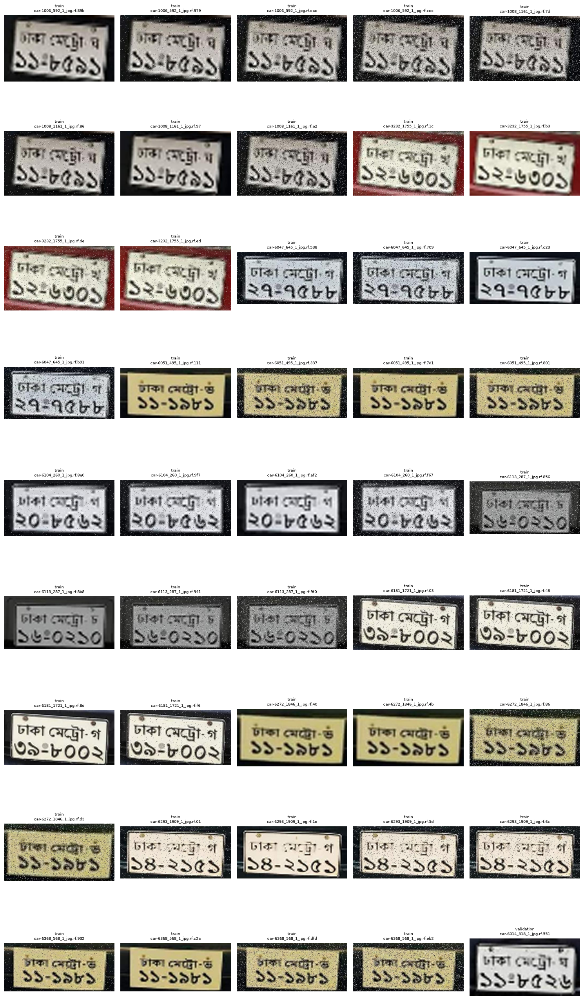


FAMILY 2 | Images: 29 | Unique pHashes: 20


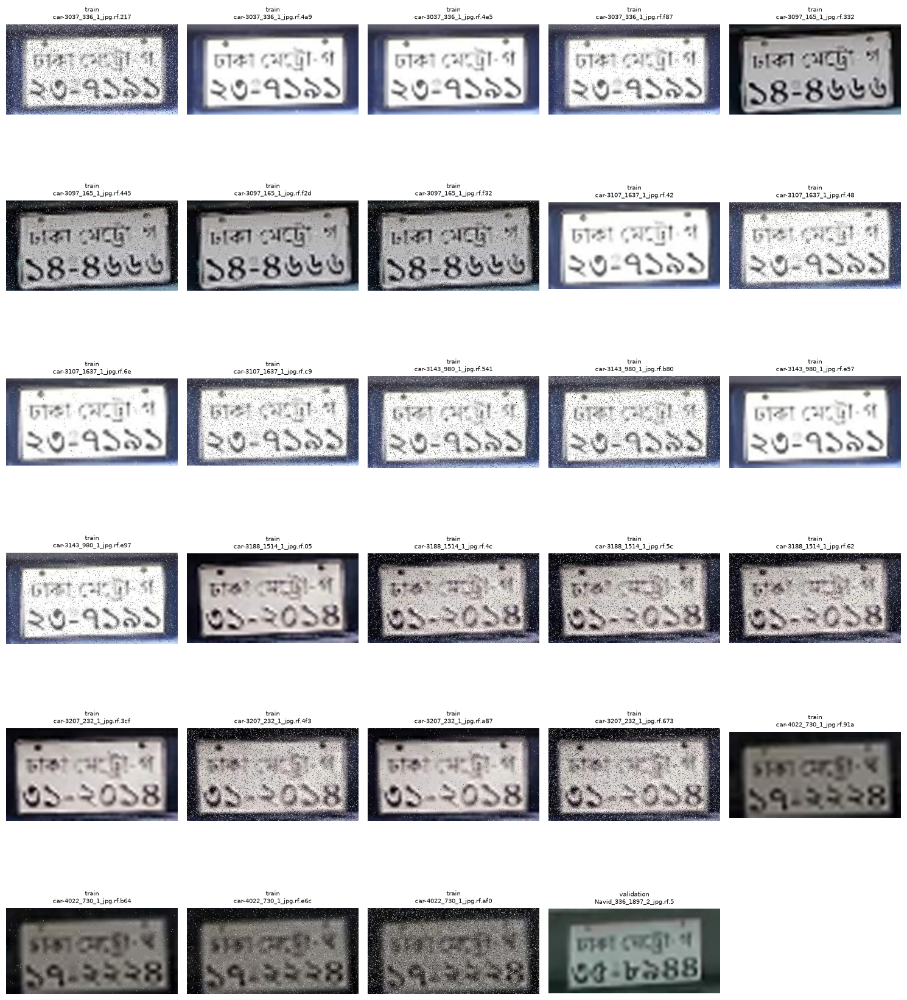


FAMILY 3 | Images: 20 | Unique pHashes: 8


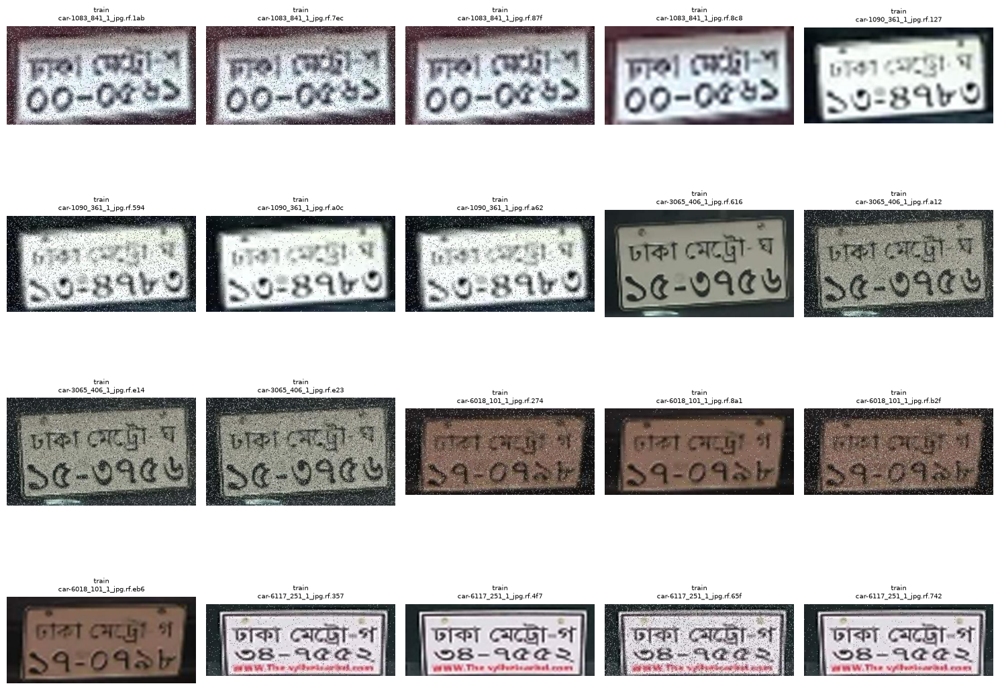


FAMILY 4 | Images: 13 | Unique pHashes: 10


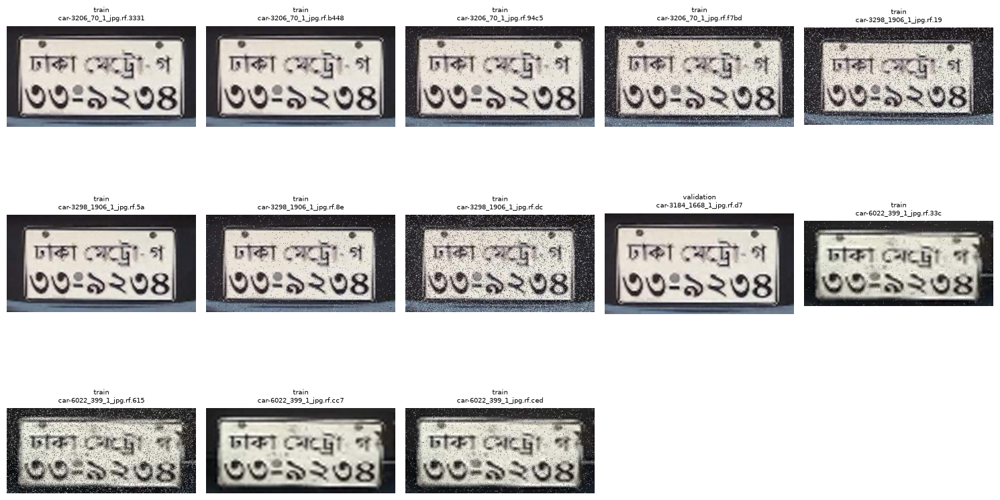


FAMILY 5 | Images: 13 | Unique pHashes: 9


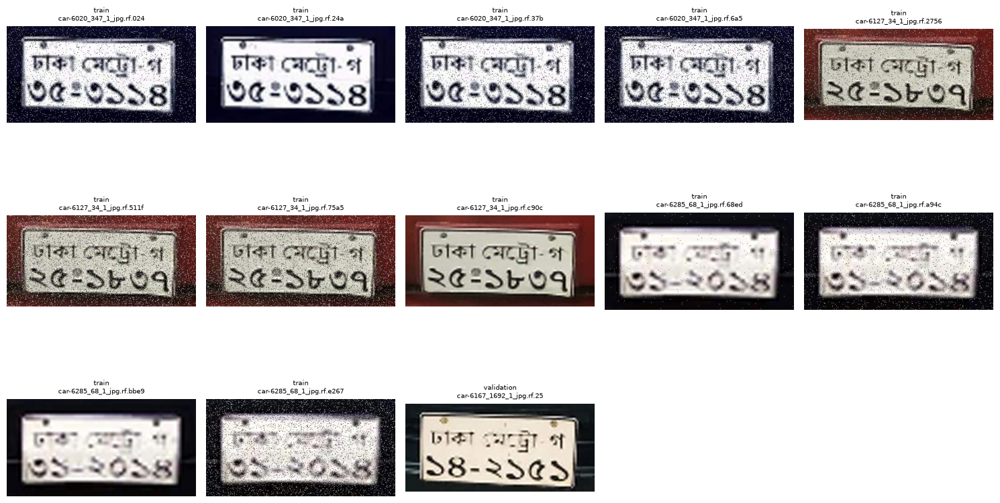


FAMILY 6 | Images: 12 | Unique pHashes: 6


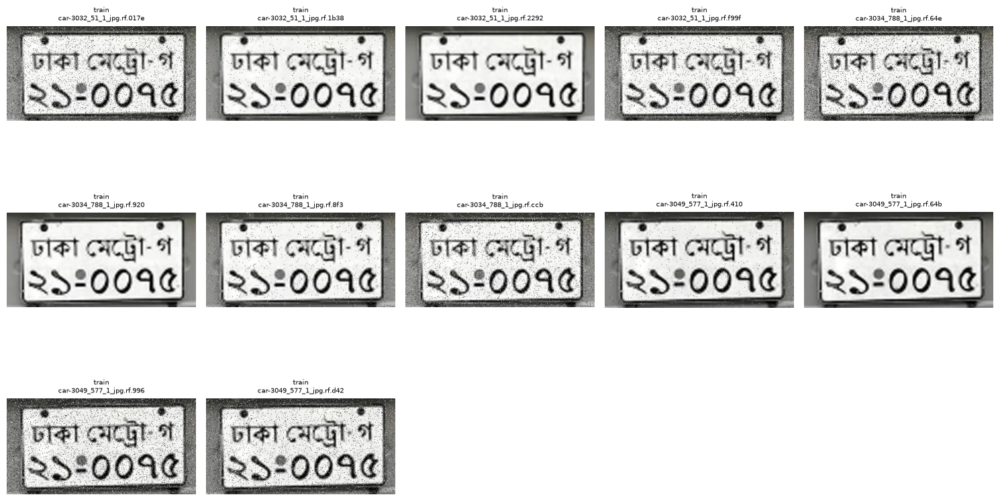


FAMILY 7 | Images: 12 | Unique pHashes: 8


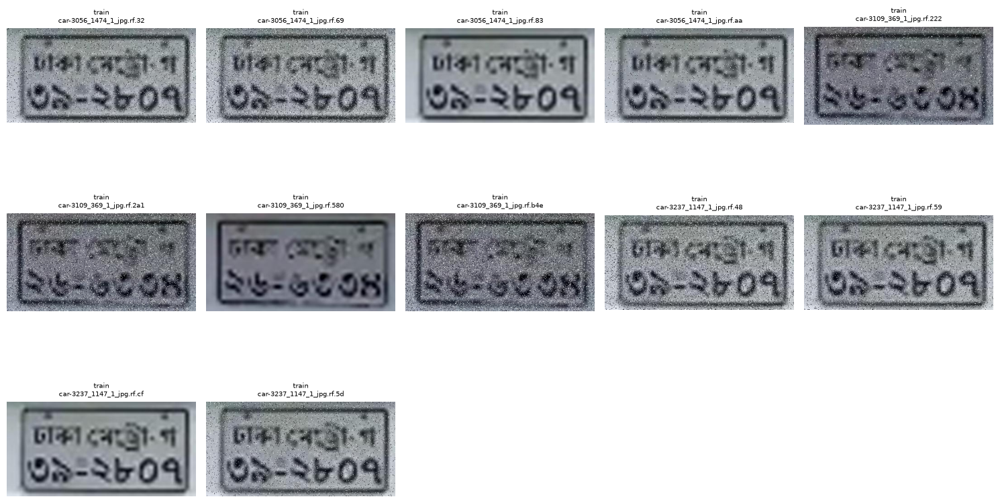

In [58]:
import matplotlib.pyplot as plt
import math

large_char_families_sorted = sorted(
    large_char_families,
    key=lambda x: len(x["records"]),
    reverse=True
)

for family_number, family in enumerate(
    large_char_families_sorted,
    start=1
):

    records = family["records"]

    print(
        f"\nFAMILY {family_number} | "
        f"Images: {len(records)} | "
        f"Unique pHashes: {len(family['hashes'])}"
    )

    cols = 5
    rows = math.ceil(len(records) / cols)

    plt.figure(
        figsize=(15, rows * 3)
    )

    for i, record in enumerate(records):

        image_path = record["path"]

        with Image.open(image_path) as img:
            display_img = img.convert("RGB").copy()

        plt.subplot(
            rows,
            cols,
            i + 1
        )

        plt.imshow(display_img)
        plt.axis("off")

        plt.title(
            f"{record['split']}\n"
            f"{record['filename'][:25]}",
            fontsize=7
        )

    plt.tight_layout()
    plt.show()

Exact pHash cross-split groups: 3

GROUP 1 | pHash: d4442b4b2e3e3e95 | Images: 2


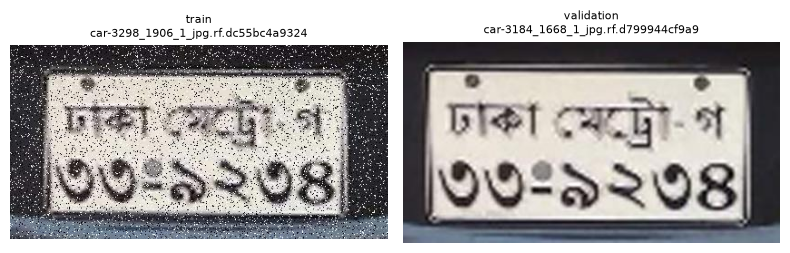


GROUP 2 | pHash: d4c06b6b6a6a2e95 | Images: 2


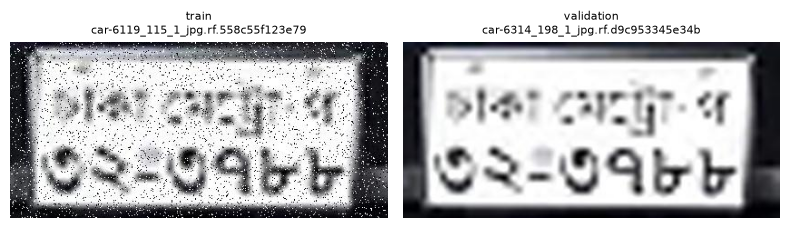


GROUP 3 | pHash: 80ba7b013e7e3ec1 | Images: 2


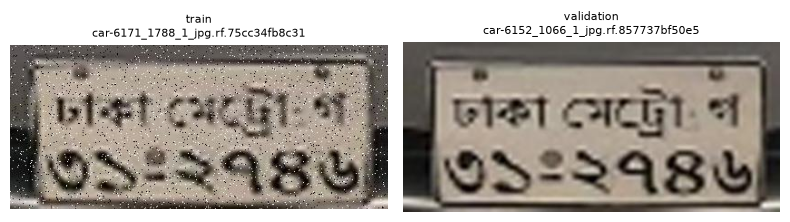

In [59]:
print(
    "Exact pHash cross-split groups:",
    len(char_exact_phash_cross)
)

for group_number, (phash, records) in enumerate(
    char_exact_phash_cross,
    start=1
):

    print(
        f"\nGROUP {group_number} | "
        f"pHash: {phash} | "
        f"Images: {len(records)}"
    )

    cols = min(4, len(records))
    rows = math.ceil(len(records) / cols)

    plt.figure(
        figsize=(cols * 4, rows * 3)
    )

    for i, record in enumerate(records):

        with Image.open(record["path"]) as img:
            display_img = img.convert("RGB").copy()

        plt.subplot(
            rows,
            cols,
            i + 1
        )

        plt.imshow(display_img)
        plt.axis("off")

        plt.title(
            f"{record['split']}\n"
            f"{record['filename'][:35]}",
            fontsize=8
        )

    plt.tight_layout()
    plt.show()

In [60]:
final_character_root = (
    PROJECT_ROOT
    / "dataset"
    / "final_leakage_safe"
    / "Character Recognition"
)

final_character_stats = {}

for split in ["train", "validation", "test"]:

    source_folder = (
        cleaned_character_root
        / split
    )

    target_folder = (
        final_character_root
        / split
    )

    target_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    images_copied = 0
    xml_copied = 0

    images = (
        list(source_folder.glob("*.jpg"))
        + list(source_folder.glob("*.jpeg"))
        + list(source_folder.glob("*.png"))
    )

    for image_path in images:

        shutil.copy2(
            image_path,
            target_folder / image_path.name
        )

        images_copied += 1

    for xml_path in source_folder.glob("*.xml"):

        shutil.copy2(
            xml_path,
            target_folder / xml_path.name
        )

        xml_copied += 1

    final_character_stats[split] = {
        "images": images_copied,
        "xml": xml_copied
    }


print("FINAL CHARACTER DATASET CREATED")
print("===============================")

for split, stats in final_character_stats.items():

    print(
        f"{split}: "
        f"{stats['images']} images, "
        f"{stats['xml']} XML"
    )

print(
    "\nTotal images:",
    sum(
        stats["images"]
        for stats
        in final_character_stats.values()
    )
)

print("\nLocation:")
print(final_character_root)

FINAL CHARACTER DATASET CREATED
train: 3480 images, 3480 XML
validation: 363 images, 363 XML
test: 218 images, 218 XML

Total images: 4061

Location:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\final_leakage_safe\Character Recognition


In [61]:
print("FINAL CHARACTER CLASSES")
print("=======================")

for index, class_name in enumerate(
    all_character_classes
):
    print(
        f"{index:2d}: {class_name}"
    )

print(
    "\nTotal classes:",
    len(all_character_classes)
)

FINAL CHARACTER CLASSES
 0: 0
 1: 1
 2: 2
 3: 3
 4: 4
 5: 5
 6: 6
 7: 7
 8: 8
 9: 9
10: ba
11: ca
12: chattogram
13: da
14: dhaka
15: ga
16: gha
17: ha
18: ja
19: jashore
20: ka
21: kha
22: khulna
23: metro
24: na
25: ta
26: va

Total classes: 27


In [62]:
print(all_character_classes)
print("Total:", len(all_character_classes))

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'ba', 'ca', 'chattogram', 'da', 'dhaka', 'ga', 'gha', 'ha', 'ja', 'jashore', 'ka', 'kha', 'khulna', 'metro', 'na', 'ta', 'va']
Total: 27


In [63]:
import json

class_mapping = {
    index: class_name
    for index, class_name
    in enumerate(all_character_classes)
}

mapping_path = (
    PROJECT_ROOT
    / "dataset"
    / "final_leakage_safe"
    / "character_classes.json"
)

with open(
    mapping_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        class_mapping,
        f,
        indent=4,
        ensure_ascii=False
    )


print("CHARACTER CLASS MAPPING SAVED")
print("=============================")

print("Classes:", len(class_mapping))
print("Location:")
print(mapping_path)

print("\nMapping:")

for class_id, class_name in class_mapping.items():
    print(
        f"{class_id}: {class_name}"
    )

CHARACTER CLASS MAPPING SAVED
Classes: 27
Location:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\final_leakage_safe\character_classes.json

Mapping:
0: 0
1: 1
2: 2
3: 3
4: 4
5: 5
6: 6
7: 7
8: 8
9: 9
10: ba
11: ca
12: chattogram
13: da
14: dhaka
15: ga
16: gha
17: ha
18: ja
19: jashore
20: ka
21: kha
22: khulna
23: metro
24: na
25: ta
26: va


In [64]:
final_loc_summary = {}

for split in ["train", "validation", "test"]:

    folder = final_safe_root / split

    positive = 0
    negative = 0
    objects = 0

    for xml_path in folder.glob("*.xml"):

        root = ET.parse(xml_path).getroot()

        xml_objects = root.findall("object")

        if len(xml_objects) > 0:
            positive += 1
        else:
            negative += 1

        objects += len(xml_objects)

    final_loc_summary[split] = {
        "positive": positive,
        "negative": negative,
        "objects": objects
    }


print("FINAL LOCALIZATION ANNOTATION SUMMARY")
print("=====================================")

for split, stats in final_loc_summary.items():

    print(
        f"{split}: "
        f"positive={stats['positive']}, "
        f"negative={stats['negative']}, "
        f"objects={stats['objects']}"
    )


print("\nTOTAL")

print(
    "Positive:",
    sum(
        x["positive"]
        for x in final_loc_summary.values()
    )
)

print(
    "Negative:",
    sum(
        x["negative"]
        for x in final_loc_summary.values()
    )
)

print(
    "Objects:",
    sum(
        x["objects"]
        for x in final_loc_summary.values()
    )
)

FINAL LOCALIZATION ANNOTATION SUMMARY
train: positive=3745, negative=1379, objects=3798
validation: positive=446, negative=194, objects=450
test: positive=469, negative=172, objects=485

TOTAL
Positive: 4660
Negative: 1745
Objects: 4733


In [65]:
yolo_localization_root = (
    PROJECT_ROOT
    / "dataset"
    / "yolo"
    / "License Plate Localization"
)

for split in ["train", "validation", "test"]:

    (yolo_localization_root / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (yolo_localization_root / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )


print("YOLO LOCALIZATION STRUCTURE CREATED")
print("===================================")

print(yolo_localization_root)

print("\nStructure:")
print("images/train")
print("images/validation")
print("images/test")
print("labels/train")
print("labels/validation")
print("labels/test")

YOLO LOCALIZATION STRUCTURE CREATED
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\yolo\License Plate Localization

Structure:
images/train
images/validation
images/test
labels/train
labels/validation
labels/test


In [66]:
# Find one positive XML sample
sample_xml = None

train_folder = (
    final_safe_root
    / "train"
)

for xml_path in train_folder.glob("*.xml"):

    root = ET.parse(xml_path).getroot()

    if root.find("object") is not None:
        sample_xml = xml_path
        break


# Read XML
root = ET.parse(sample_xml).getroot()

size = root.find("size")

img_width = int(size.find("width").text)
img_height = int(size.find("height").text)

obj = root.find("object")
box = obj.find("bndbox")

xmin = float(box.find("xmin").text)
ymin = float(box.find("ymin").text)
xmax = float(box.find("xmax").text)
ymax = float(box.find("ymax").text)


# Pascal VOC -> YOLO
x_center = ((xmin + xmax) / 2) / img_width
y_center = ((ymin + ymax) / 2) / img_height

box_width = (xmax - xmin) / img_width
box_height = (ymax - ymin) / img_height


print("SAMPLE VOC -> YOLO CONVERSION")
print("=============================")

print("XML:", sample_xml.name)
print("Image size:", img_width, "x", img_height)

print("\nVOC box:")
print(
    "xmin =", xmin,
    "ymin =", ymin,
    "xmax =", xmax,
    "ymax =", ymax
)

print("\nYOLO label:")
print(
    f"0 "
    f"{x_center:.6f} "
    f"{y_center:.6f} "
    f"{box_width:.6f} "
    f"{box_height:.6f}"
)

print("\nRange check:")
print(
    "x_center valid:",
    0 <= x_center <= 1
)
print(
    "y_center valid:",
    0 <= y_center <= 1
)
print(
    "width valid:",
    0 < box_width <= 1
)
print(
    "height valid:",
    0 < box_height <= 1
)

SAMPLE VOC -> YOLO CONVERSION
XML: 100_jpg.rf.f9307511bd7e18e9f7ebd8f15ecc79e4.xml
Image size: 960 x 708

VOC box:
xmin = 363.0 ymin = 466.0 xmax = 508.0 ymax = 543.0

YOLO label:
0 0.453646 0.712571 0.151042 0.108757

Range check:
x_center valid: True
y_center valid: True
width valid: True
height valid: True


In [67]:
import shutil
import xml.etree.ElementTree as ET

source_root = (
    PROJECT_ROOT
    / "dataset"
    / "final_leakage_safe"
    / "License Plate Localization"
)

yolo_root = (
    PROJECT_ROOT
    / "dataset"
    / "yolo"
    / "License Plate Localization"
)

conversion_stats = {}

for split in ["train", "validation", "test"]:

    source_folder = source_root / split
    image_output = yolo_root / "images" / split
    label_output = yolo_root / "labels" / split

    images = (
        list(source_folder.glob("*.jpg"))
        + list(source_folder.glob("*.jpeg"))
        + list(source_folder.glob("*.png"))
    )

    images_copied = 0
    labels_created = 0
    objects_converted = 0
    empty_labels = 0

    for image_path in images:

        xml_path = image_path.with_suffix(".xml")

        shutil.copy2(
            image_path,
            image_output / image_path.name
        )

        images_copied += 1

        root = ET.parse(xml_path).getroot()

        size = root.find("size")

        img_width = float(size.find("width").text)
        img_height = float(size.find("height").text)

        yolo_lines = []

        for obj in root.findall("object"):

            box = obj.find("bndbox")

            xmin = float(box.find("xmin").text)
            ymin = float(box.find("ymin").text)
            xmax = float(box.find("xmax").text)
            ymax = float(box.find("ymax").text)

            x_center = ((xmin + xmax) / 2) / img_width
            y_center = ((ymin + ymax) / 2) / img_height

            box_width = (xmax - xmin) / img_width
            box_height = (ymax - ymin) / img_height

            yolo_lines.append(
                f"0 "
                f"{x_center:.6f} "
                f"{y_center:.6f} "
                f"{box_width:.6f} "
                f"{box_height:.6f}"
            )

            objects_converted += 1

        label_path = (
            label_output
            / f"{image_path.stem}.txt"
        )

        with open(
            label_path,
            "w",
            encoding="utf-8"
        ) as f:

            if yolo_lines:
                f.write("\n".join(yolo_lines))
            else:
                empty_labels += 1

        labels_created += 1

    conversion_stats[split] = {
        "images": images_copied,
        "labels": labels_created,
        "objects": objects_converted,
        "empty": empty_labels
    }


print("LOCALIZATION YOLO CONVERSION COMPLETE")
print("=====================================")

for split, stats in conversion_stats.items():

    print(
        f"{split}: "
        f"images={stats['images']}, "
        f"labels={stats['labels']}, "
        f"objects={stats['objects']}, "
        f"empty_labels={stats['empty']}"
    )

print("\nTOTAL")

print(
    "Images:",
    sum(x["images"] for x in conversion_stats.values())
)

print(
    "Labels:",
    sum(x["labels"] for x in conversion_stats.values())
)

print(
    "Objects:",
    sum(x["objects"] for x in conversion_stats.values())
)

print(
    "Empty labels:",
    sum(x["empty"] for x in conversion_stats.values())
)

LOCALIZATION YOLO CONVERSION COMPLETE
train: images=5124, labels=5124, objects=3798, empty_labels=1379
validation: images=640, labels=640, objects=450, empty_labels=194
test: images=641, labels=641, objects=485, empty_labels=172

TOTAL
Images: 6405
Labels: 6405
Objects: 4733
Empty labels: 1745


In [68]:
yolo_root = (
    PROJECT_ROOT
    / "dataset"
    / "yolo"
    / "License Plate Localization"
)

total_images = 0
total_labels = 0
total_boxes = 0

empty_labels = 0
invalid_labels = 0
missing_labels = 0

problems = []

for split in ["train", "validation", "test"]:

    image_folder = yolo_root / "images" / split
    label_folder = yolo_root / "labels" / split

    images = (
        list(image_folder.glob("*.jpg"))
        + list(image_folder.glob("*.jpeg"))
        + list(image_folder.glob("*.png"))
    )

    for image_path in images:

        total_images += 1

        label_path = (
            label_folder
            / f"{image_path.stem}.txt"
        )

        if not label_path.exists():
            missing_labels += 1
            problems.append(
                f"Missing label: {image_path.name}"
            )
            continue

        total_labels += 1

        text = label_path.read_text(
            encoding="utf-8"
        ).strip()

        if not text:
            empty_labels += 1
            continue

        for line_number, line in enumerate(
            text.splitlines(),
            start=1
        ):

            parts = line.split()

            if len(parts) != 5:
                invalid_labels += 1
                problems.append(
                    f"{label_path.name} line {line_number}: "
                    f"expected 5 values"
                )
                continue

            try:
                class_id = int(parts[0])

                x_center = float(parts[1])
                y_center = float(parts[2])
                width = float(parts[3])
                height = float(parts[4])

            except ValueError:

                invalid_labels += 1
                problems.append(
                    f"{label_path.name} line {line_number}: "
                    f"non-numeric value"
                )
                continue

            valid = (
                class_id == 0
                and 0 <= x_center <= 1
                and 0 <= y_center <= 1
                and 0 < width <= 1
                and 0 < height <= 1
            )

            if not valid:
                invalid_labels += 1
                problems.append(
                    f"{label_path.name} line {line_number}: "
                    f"invalid values"
                )
                continue

            total_boxes += 1


print("YOLO LOCALIZATION VALIDATION")
print("============================")

print("Images:", total_images)
print("Labels:", total_labels)
print("Boxes:", total_boxes)
print("Empty labels:", empty_labels)

print("\nProblems")
print("Missing labels:", missing_labels)
print("Invalid labels:", invalid_labels)

if problems:
    print("\nFirst problems:")
    for problem in problems[:10]:
        print(problem)
else:
    print("\nAll YOLO labels are valid.")

YOLO LOCALIZATION VALIDATION
Images: 6405
Labels: 6405
Boxes: 4733
Empty labels: 1745

Problems
Missing labels: 0
Invalid labels: 0

All YOLO labels are valid.


In [69]:
localization_yaml = (
    yolo_root
    / "data.yaml"
)

yaml_content = f"""path: {yolo_root.as_posix()}
train: images/train
val: images/validation
test: images/test

names:
  0: license_plate
"""

with open(
    localization_yaml,
    "w",
    encoding="utf-8"
) as f:
    f.write(yaml_content)


print("LOCALIZATION DATA.YAML CREATED")
print("==============================")

print("Location:")
print(localization_yaml)

print("\nContents:")
print(
    localization_yaml.read_text(
        encoding="utf-8"
    )
)

LOCALIZATION DATA.YAML CREATED
Location:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\yolo\License Plate Localization\data.yaml

Contents:
path: d:/Documents/Ml project/Bangladesh_License_Plate_Recognition/dataset/yolo/License Plate Localization
train: images/train
val: images/validation
test: images/test

names:
  0: license_plate



In [70]:
import sys

print("TRAINING ENVIRONMENT CHECK")
print("==========================")

print("Python:")
print(sys.version)

print("\nPython executable:")
print(sys.executable)

print("\nPyTorch:")

try:
    import torch

    print("Version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("CUDA version:", torch.version.cuda)
        print(
            "GPU:",
            torch.cuda.get_device_name(0)
        )
    else:
        print("GPU: CUDA GPU not currently available")

except ImportError:
    print("PyTorch is NOT installed.")

TRAINING ENVIRONMENT CHECK
Python:
3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]

Python executable:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\.venv\Scripts\python.exe

PyTorch:
PyTorch is NOT installed.


In [71]:
import subprocess

print("GPU HARDWARE INFORMATION")
print("========================")

result = subprocess.run(
    [
        "powershell",
        "-Command",
        "Get-CimInstance Win32_VideoController | Select-Object Name, AdapterRAM"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

print("\nNVIDIA CUDA CHECK")
print("=================")

try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True
    )

    if result.returncode == 0:
        print(result.stdout)
    else:
        print("NVIDIA CUDA GPU not detected.")

except FileNotFoundError:
    print("NVIDIA driver utility not found.")

GPU HARDWARE INFORMATION

Name                     AdapterRAM
----                     ----------
Intel(R) HD Graphics 520 1073741824




NVIDIA CUDA CHECK
NVIDIA driver utility not found.


In [72]:
import subprocess
import sys

print("PIP ENVIRONMENT CHECK")
print("=====================")

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "--version"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

print("Python executable:")
print(sys.executable)

PIP ENVIRONMENT CHECK
pip 26.2.1 from d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\.venv\Lib\site-packages\pip (python 3.14)


Python executable:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\.venv\Scripts\python.exe


In [73]:
yolo_character_root = (
    PROJECT_ROOT
    / "dataset"
    / "yolo"
    / "Character Recognition"
)

for split in ["train", "validation", "test"]:

    (yolo_character_root / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (yolo_character_root / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )


print("YOLO CHARACTER STRUCTURE CREATED")
print("================================")

print(yolo_character_root)

print("\nStructure:")
print("images/train")
print("images/validation")
print("images/test")
print("labels/train")
print("labels/validation")
print("labels/test")

YOLO CHARACTER STRUCTURE CREATED
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\yolo\Character Recognition

Structure:
images/train
images/validation
images/test
labels/train
labels/validation
labels/test


In [74]:
import json
import xml.etree.ElementTree as ET

character_root = (
    PROJECT_ROOT
    / "dataset"
    / "final_leakage_safe"
    / "Character Recognition"
)

mapping_path = (
    PROJECT_ROOT
    / "dataset"
    / "final_leakage_safe"
    / "character_classes.json"
)

with open(
    mapping_path,
    "r",
    encoding="utf-8"
) as f:
    saved_mapping = json.load(f)

class_to_id = {
    class_name: int(class_id)
    for class_id, class_name
    in saved_mapping.items()
}


sample_xml = next(
    (character_root / "train").glob("*.xml")
)

root = ET.parse(sample_xml).getroot()

size = root.find("size")

img_width = float(size.find("width").text)
img_height = float(size.find("height").text)

print("CHARACTER VOC -> YOLO SAMPLE")
print("============================")

print("XML:", sample_xml.name)
print(
    "Image size:",
    int(img_width),
    "x",
    int(img_height)
)

print("\nObjects:")

all_valid = True

for obj in root.findall("object"):

    class_name = obj.find("name").text.strip()
    class_id = class_to_id[class_name]

    box = obj.find("bndbox")

    xmin = float(box.find("xmin").text)
    ymin = float(box.find("ymin").text)
    xmax = float(box.find("xmax").text)
    ymax = float(box.find("ymax").text)

    x_center = ((xmin + xmax) / 2) / img_width
    y_center = ((ymin + ymax) / 2) / img_height
    box_width = (xmax - xmin) / img_width
    box_height = (ymax - ymin) / img_height

    valid = (
        0 <= class_id < 27
        and 0 <= x_center <= 1
        and 0 <= y_center <= 1
        and 0 < box_width <= 1
        and 0 < box_height <= 1
    )

    if not valid:
        all_valid = False

    print(
        f"{class_name:12s} -> "
        f"{class_id:2d}  "
        f"{x_center:.6f} "
        f"{y_center:.6f} "
        f"{box_width:.6f} "
        f"{box_height:.6f}"
    )

print("\nAll objects valid:", all_valid)

CHARACTER VOC -> YOLO SAMPLE
XML: 100_125_1_jpg.rf.6b58ed831c4995270bbeeab9a5189d46.xml
Image size: 416 x 194

Objects:
dhaka        -> 14  0.278846 0.409794 0.264423 0.304124
metro        -> 23  0.573317 0.430412 0.324519 0.345361
gha          -> 16  0.816106 0.438144 0.098558 0.278351
1            ->  1  0.186298 0.724227 0.132212 0.335052
3            ->  3  0.305288 0.742268 0.110577 0.371134
3            ->  3  0.487981 0.742268 0.110577 0.371134
5            ->  5  0.597356 0.755155 0.098558 0.355670
9            ->  9  0.707933 0.752577 0.127404 0.340206
8            ->  8  0.828125 0.757732 0.112981 0.319588

All objects valid: True


In [75]:
import shutil
import xml.etree.ElementTree as ET

source_root = (
    PROJECT_ROOT
    / "dataset"
    / "final_leakage_safe"
    / "Character Recognition"
)

yolo_root_char = (
    PROJECT_ROOT
    / "dataset"
    / "yolo"
    / "Character Recognition"
)

conversion_stats = {}

for split in ["train", "validation", "test"]:

    source_folder = source_root / split
    image_output = yolo_root_char / "images" / split
    label_output = yolo_root_char / "labels" / split

    images = (
        list(source_folder.glob("*.jpg"))
        + list(source_folder.glob("*.jpeg"))
        + list(source_folder.glob("*.png"))
    )

    images_copied = 0
    labels_created = 0
    objects_converted = 0

    for image_path in images:

        xml_path = image_path.with_suffix(".xml")

        shutil.copy2(
            image_path,
            image_output / image_path.name
        )

        root = ET.parse(xml_path).getroot()

        size = root.find("size")

        img_width = float(size.find("width").text)
        img_height = float(size.find("height").text)

        yolo_lines = []

        for obj in root.findall("object"):

            class_name = obj.find("name").text.strip()

            if class_name not in class_to_id:
                raise ValueError(
                    f"Unknown class '{class_name}' "
                    f"in {xml_path.name}"
                )

            class_id = class_to_id[class_name]

            box = obj.find("bndbox")

            xmin = float(box.find("xmin").text)
            ymin = float(box.find("ymin").text)
            xmax = float(box.find("xmax").text)
            ymax = float(box.find("ymax").text)

            x_center = ((xmin + xmax) / 2) / img_width
            y_center = ((ymin + ymax) / 2) / img_height
            box_width = (xmax - xmin) / img_width
            box_height = (ymax - ymin) / img_height

            yolo_lines.append(
                f"{class_id} "
                f"{x_center:.6f} "
                f"{y_center:.6f} "
                f"{box_width:.6f} "
                f"{box_height:.6f}"
            )

            objects_converted += 1

        label_path = (
            label_output
            / f"{image_path.stem}.txt"
        )

        with open(
            label_path,
            "w",
            encoding="utf-8"
        ) as f:
            f.write("\n".join(yolo_lines))

        images_copied += 1
        labels_created += 1

    conversion_stats[split] = {
        "images": images_copied,
        "labels": labels_created,
        "objects": objects_converted
    }


print("CHARACTER YOLO CONVERSION COMPLETE")
print("==================================")

for split, stats in conversion_stats.items():

    print(
        f"{split}: "
        f"images={stats['images']}, "
        f"labels={stats['labels']}, "
        f"objects={stats['objects']}"
    )

print("\nTOTAL")

print(
    "Images:",
    sum(x["images"] for x in conversion_stats.values())
)

print(
    "Labels:",
    sum(x["labels"] for x in conversion_stats.values())
)

print(
    "Objects:",
    sum(x["objects"] for x in conversion_stats.values())
)

CHARACTER YOLO CONVERSION COMPLETE
train: images=3480, labels=3480, objects=30604
validation: images=363, labels=363, objects=3180
test: images=218, labels=218, objects=1921

TOTAL
Images: 4061
Labels: 4061
Objects: 35705


In [76]:
total_images = 0
total_labels = 0
total_boxes = 0

missing_labels = 0
empty_labels = 0
invalid_labels = 0
unknown_class_ids = 0

class_counts = {
    i: 0
    for i in range(27)
}

problems = []

for split in ["train", "validation", "test"]:

    image_folder = (
        yolo_root_char
        / "images"
        / split
    )

    label_folder = (
        yolo_root_char
        / "labels"
        / split
    )

    images = (
        list(image_folder.glob("*.jpg"))
        + list(image_folder.glob("*.jpeg"))
        + list(image_folder.glob("*.png"))
    )

    for image_path in images:

        total_images += 1

        label_path = (
            label_folder
            / f"{image_path.stem}.txt"
        )

        if not label_path.exists():

            missing_labels += 1

            problems.append(
                f"Missing label: {image_path.name}"
            )

            continue

        total_labels += 1

        text = label_path.read_text(
            encoding="utf-8"
        ).strip()

        if not text:

            empty_labels += 1
            problems.append(
                f"Empty label: {label_path.name}"
            )

            continue

        for line_number, line in enumerate(
            text.splitlines(),
            start=1
        ):

            parts = line.split()

            if len(parts) != 5:

                invalid_labels += 1

                problems.append(
                    f"{label_path.name} "
                    f"line {line_number}: "
                    f"expected 5 values"
                )

                continue

            try:

                class_id = int(parts[0])

                x_center = float(parts[1])
                y_center = float(parts[2])
                width = float(parts[3])
                height = float(parts[4])

            except ValueError:

                invalid_labels += 1

                problems.append(
                    f"{label_path.name} "
                    f"line {line_number}: "
                    f"non-numeric value"
                )

                continue

            if class_id not in class_counts:

                unknown_class_ids += 1

                problems.append(
                    f"{label_path.name} "
                    f"line {line_number}: "
                    f"unknown class {class_id}"
                )

                continue

            valid_box = (
                0 <= x_center <= 1
                and 0 <= y_center <= 1
                and 0 < width <= 1
                and 0 < height <= 1
            )

            if not valid_box:

                invalid_labels += 1

                problems.append(
                    f"{label_path.name} "
                    f"line {line_number}: "
                    f"invalid coordinates"
                )

                continue

            class_counts[class_id] += 1
            total_boxes += 1


print("YOLO CHARACTER VALIDATION")
print("=========================")

print("Images:", total_images)
print("Labels:", total_labels)
print("Boxes:", total_boxes)

print("\nProblems")
print("Missing labels:", missing_labels)
print("Empty labels:", empty_labels)
print("Invalid labels:", invalid_labels)
print("Unknown class IDs:", unknown_class_ids)

print("\nClasses detected:", len([
    x for x in class_counts.values()
    if x > 0
]))

if problems:
    print("\nFirst problems:")

    for problem in problems[:10]:
        print(problem)

else:
    print("\nAll Character YOLO labels are valid.")

YOLO CHARACTER VALIDATION
Images: 4061
Labels: 4061
Boxes: 35705

Problems
Missing labels: 0
Empty labels: 0
Invalid labels: 0
Unknown class IDs: 0

Classes detected: 27

All Character YOLO labels are valid.


In [77]:
character_yaml = (
    yolo_root_char
    / "data.yaml"
)

yaml_lines = [
    f"path: {yolo_root_char.as_posix()}",
    "train: images/train",
    "val: images/validation",
    "test: images/test",
    "",
    "names:"
]

for class_id in range(27):
    class_name = saved_mapping[str(class_id)]

    yaml_lines.append(
        f"  {class_id}: {class_name}"
    )

yaml_content = "\n".join(yaml_lines) + "\n"

with open(
    character_yaml,
    "w",
    encoding="utf-8"
) as f:
    f.write(yaml_content)


print("CHARACTER DATA.YAML CREATED")
print("===========================")

print("Location:")
print(character_yaml)

print("\nContents:")
print(
    character_yaml.read_text(
        encoding="utf-8"
    )
)

CHARACTER DATA.YAML CREATED
Location:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\yolo\Character Recognition\data.yaml

Contents:
path: d:/Documents/Ml project/Bangladesh_License_Plate_Recognition/dataset/yolo/Character Recognition
train: images/train
val: images/validation
test: images/test

names:
  0: 0
  1: 1
  2: 2
  3: 3
  4: 4
  5: 5
  6: 6
  7: 7
  8: 8
  9: 9
  10: ba
  11: ca
  12: chattogram
  13: da
  14: dhaka
  15: ga
  16: gha
  17: ha
  18: ja
  19: jashore
  20: ka
  21: kha
  22: khulna
  23: metro
  24: na
  25: ta
  26: va



In [78]:
%pip install pyyaml

  Using cached pyyaml-6.0.3-cp314-cp314-win_amd64.whl.metadata (2.4 kB)
Using cached pyyaml-6.0.3-cp314-cp314-win_amd64.whl (156 kB)
Note: you may need to restart the kernel to use updated packages.


In [79]:
import yaml

with open(
    character_yaml,
    "r",
    encoding="utf-8"
) as f:
    config = yaml.safe_load(f)

print("YAML CLASS CHECK")
print("================")

print("Total classes:", len(config["names"]))

for class_id, class_name in config["names"].items():
    print(
        class_id,
        "->",
        repr(class_name),
        "| type:",
        type(class_name).__name__
    )

YAML CLASS CHECK
Total classes: 27
0 -> 0 | type: int
1 -> 1 | type: int
2 -> 2 | type: int
3 -> 3 | type: int
4 -> 4 | type: int
5 -> 5 | type: int
6 -> 6 | type: int
7 -> 7 | type: int
8 -> 8 | type: int
9 -> 9 | type: int
10 -> 'ba' | type: str
11 -> 'ca' | type: str
12 -> 'chattogram' | type: str
13 -> 'da' | type: str
14 -> 'dhaka' | type: str
15 -> 'ga' | type: str
16 -> 'gha' | type: str
17 -> 'ha' | type: str
18 -> 'ja' | type: str
19 -> 'jashore' | type: str
20 -> 'ka' | type: str
21 -> 'kha' | type: str
22 -> 'khulna' | type: str
23 -> 'metro' | type: str
24 -> 'na' | type: str
25 -> 'ta' | type: str
26 -> 'va' | type: str


In [80]:
yaml_lines = [
    f"path: {yolo_root_char.as_posix()}",
    "train: images/train",
    "val: images/validation",
    "test: images/test",
    "",
    "names:"
]

for class_id in range(27):

    class_name = saved_mapping[str(class_id)]

    yaml_lines.append(
        f'  {class_id}: "{class_name}"'
    )

yaml_content = "\n".join(yaml_lines) + "\n"

with open(
    character_yaml,
    "w",
    encoding="utf-8"
) as f:
    f.write(yaml_content)


print("CHARACTER DATA.YAML UPDATED")
print("===========================")

with open(
    character_yaml,
    "r",
    encoding="utf-8"
) as f:
    config = yaml.safe_load(f)

print("Total classes:", len(config["names"]))

all_strings = True

for class_id, class_name in config["names"].items():

    print(
        class_id,
        "->",
        repr(class_name),
        "| type:",
        type(class_name).__name__
    )

    if not isinstance(class_name, str):
        all_strings = False

print("\nAll class names are strings:", all_strings)

CHARACTER DATA.YAML UPDATED
Total classes: 27
0 -> '0' | type: str
1 -> '1' | type: str
2 -> '2' | type: str
3 -> '3' | type: str
4 -> '4' | type: str
5 -> '5' | type: str
6 -> '6' | type: str
7 -> '7' | type: str
8 -> '8' | type: str
9 -> '9' | type: str
10 -> 'ba' | type: str
11 -> 'ca' | type: str
12 -> 'chattogram' | type: str
13 -> 'da' | type: str
14 -> 'dhaka' | type: str
15 -> 'ga' | type: str
16 -> 'gha' | type: str
17 -> 'ha' | type: str
18 -> 'ja' | type: str
19 -> 'jashore' | type: str
20 -> 'ka' | type: str
21 -> 'kha' | type: str
22 -> 'khulna' | type: str
23 -> 'metro' | type: str
24 -> 'na' | type: str
25 -> 'ta' | type: str
26 -> 'va' | type: str

All class names are strings: True


In [81]:
summary_path = (
    PROJECT_ROOT
    / "dataset"
    / "final_leakage_safe"
    / "dataset_summary.txt"
)

summary_text = """BANGLADESH LICENSE PLATE RECOGNITION
DATASET PREPARATION SUMMARY
====================================

1. LICENSE PLATE LOCALIZATION
-----------------------------
Train images: 5124
Validation images: 640
Test images: 641
Total images: 6405

Positive images: 4660
Negative images: 1745
Plate objects: 4733

Classes: 1
0 = license_plate

Cross-split exact MD5 leakage: 0
Cross-split exact pHash leakage: 0
Cross-split near-pHash <= 4 leakage: 0

YOLO labels validated: YES
Invalid YOLO labels: 0


2. CHARACTER RECOGNITION
------------------------
Train images: 3480
Validation images: 363
Test images: 218
Total images: 4061

Character objects: 35705
Classes: 27

0 = 0
1 = 1
2 = 2
3 = 3
4 = 4
5 = 5
6 = 6
7 = 7
8 = 8
9 = 9
10 = ba
11 = ca
12 = chattogram
13 = da
14 = dhaka
15 = ga
16 = gha
17 = ha
18 = ja
19 = jashore
20 = ka
21 = kha
22 = khulna
23 = metro
24 = na
25 = ta
26 = va

Cross-split exact MD5 leakage: 0
Cross-split source-name leakage: 0

YOLO labels validated: YES
Invalid YOLO labels: 0
Missing classes: 0


3. TRAINING DATASETS
--------------------
Localization:
dataset/yolo/License Plate Localization

Character Recognition:
dataset/yolo/Character Recognition

Pipeline:
Vehicle Image
-> License Plate Localization
-> Plate Crop
-> Character Detection
-> Character Ordering
-> Final Bangladesh License Plate Text
"""

summary_path.write_text(
    summary_text,
    encoding="utf-8"
)

print("DATASET SUMMARY SAVED")
print("=====================")
print(summary_path)

print("\nFile size:", summary_path.stat().st_size, "bytes")

DATASET SUMMARY SAVED
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\final_leakage_safe\dataset_summary.txt

File size: 1421 bytes


In [82]:
def get_folder_size(folder):
    total_bytes = 0

    for file_path in folder.rglob("*"):
        if file_path.is_file():
            total_bytes += file_path.stat().st_size

    return total_bytes


localization_size = get_folder_size(
    yolo_localization_root
)

size_mb = localization_size / (1024 ** 2)
size_gb = localization_size / (1024 ** 3)

print("LOCALIZATION YOLO DATASET SIZE")
print("==============================")

print(
    f"Size: {size_mb:.2f} MB"
)

print(
    f"Size: {size_gb:.3f} GB"
)

print("\nLocation:")
print(yolo_localization_root)

LOCALIZATION YOLO DATASET SIZE
Size: 1617.10 MB
Size: 1.579 GB

Location:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\yolo\License Plate Localization


In [83]:
import shutil

zip_base = (
    PROJECT_ROOT
    / "localization_yolo_dataset"
)

zip_path = shutil.make_archive(
    str(zip_base),
    "zip",
    root_dir=yolo_localization_root
)

print("LOCALIZATION DATASET ZIP CREATED")
print("================================")

print("Location:")
print(zip_path)

zip_size = (
    Path(zip_path).stat().st_size
    / (1024 ** 3)
)

print(
    f"\nZIP size: {zip_size:.3f} GB"
)

LOCALIZATION DATASET ZIP CREATED
Location:
d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\localization_yolo_dataset.zip

ZIP size: 1.567 GB


In [84]:
import zipfile
from pathlib import Path

zip_path = (
    PROJECT_ROOT
    / "localization_yolo_dataset.zip"
)

with zipfile.ZipFile(zip_path, "r") as zf:

    bad_file = zf.testzip()
    files = [
        name for name in zf.namelist()
        if not name.endswith("/")
    ]

    image_files = [
        name for name in files
        if name.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    label_files = [
        name for name in files
        if name.startswith("labels/")
        and name.endswith(".txt")
    ]

    yaml_files = [
        name for name in files
        if name.endswith("data.yaml")
    ]


print("LOCALIZATION ZIP VERIFICATION")
print("=============================")

print(
    "ZIP integrity:",
    "PASS" if bad_file is None else "FAIL"
)

print("Images:", len(image_files))
print("Labels:", len(label_files))
print("data.yaml:", len(yaml_files))

print("\nTotal files:", len(files))

if bad_file:
    print("\nCorrupted file:", bad_file)
else:
    print("\nArchive is healthy.")

LOCALIZATION ZIP VERIFICATION
ZIP integrity: PASS
Images: 6405
Labels: 6405
data.yaml: 1

Total files: 12811

Archive is healthy.


In [85]:
from pathlib import Path

char_yolo = Path(
    "../dataset/yolo/Character Recognition"
)

total_size = sum(
    f.stat().st_size
    for f in char_yolo.rglob("*")
    if f.is_file()
)

print("Character YOLO dataset")
print("======================")
print("Exists:", char_yolo.exists())
print("Size MB:", round(total_size / (1024 ** 2), 2))
print("Size GB:", round(total_size / (1024 ** 3), 3))

for split in ["train", "validation", "test"]:
    images = list((char_yolo / "images" / split).glob("*"))
    labels = list((char_yolo / "labels" / split).glob("*.txt"))

    print(
        f"{split}:",
        len(images),
        "images |",
        len(labels),
        "labels"
    )

Character YOLO dataset
Exists: True
Size MB: 118.63
Size GB: 0.116
train: 3480 images | 3480 labels
validation: 363 images | 363 labels
test: 218 images | 218 labels


In [86]:
from pathlib import Path
import zipfile

project_root = Path(
    r"D:\Documents\Ml project\Bangladesh_License_Plate_Recognition"
)

source_folder = (
    project_root
    / "dataset"
    / "yolo"
    / "Character Recognition"
)

zip_path = (
    project_root
    / "character_yolo_dataset.zip"
)

print("Creating Character Recognition ZIP...")

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zf:

    for file in source_folder.rglob("*"):
        if file.is_file():
            relative_path = file.relative_to(source_folder)
            zf.write(file, relative_path)

print("\nZIP CREATED")
print("===========")
print("Path:", zip_path)
print(
    "Size MB:",
    round(zip_path.stat().st_size / (1024 ** 2), 2)
)

Creating Character Recognition ZIP...

ZIP CREATED
Path: D:\Documents\Ml project\Bangladesh_License_Plate_Recognition\character_yolo_dataset.zip
Size MB: 118.6


In [87]:
from pathlib import Path

project_root = Path(r"D:\Documents\Ml project\Bangladesh_License_Plate_Recognition")

loc_yolo = (
    project_root
    / "dataset"
    / "yolo"
    / "License Plate Localization"
)

print("LOCAL YOLO LOCALIZATION DATASET")
print("===============================")
print("Path:", loc_yolo)
print("Exists:", loc_yolo.exists())

for split in ["train", "validation", "test"]:
    image_dir = loc_yolo / "images" / split
    label_dir = loc_yolo / "labels" / split

    images = list(image_dir.glob("*")) if image_dir.exists() else []
    labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))

LOCAL YOLO LOCALIZATION DATASET
Path: D:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\yolo\License Plate Localization
Exists: True

TRAIN
Images: 5124
Labels: 5124

VALIDATION
Images: 640
Labels: 640

TEST
Images: 641
Labels: 641


In [88]:
import numpy as np

train_label_dir = loc_yolo / "labels" / "train"

positive_images = 0
negative_images = 0
box_widths = []
box_heights = []
box_areas = []
box_aspects = []
total_boxes = 0

for label_file in train_label_dir.glob("*.txt"):
    text = label_file.read_text(encoding="utf-8").strip()

    if not text:
        negative_images += 1
        continue

    positive_images += 1

    for line in text.splitlines():
        parts = line.split()

        if len(parts) != 5:
            continue

        _, xc, yc, w, h = map(float, parts)

        box_widths.append(w)
        box_heights.append(h)
        box_areas.append(w * h)

        if h > 0:
            box_aspects.append(w / h)

        total_boxes += 1

print("LOCALIZATION TRAINING BOX ANALYSIS")
print("==================================")
print("Positive images:", positive_images)
print("Negative images:", negative_images)
print("Total boxes:", total_boxes)

print("\nNORMALIZED BOX WIDTH")
print("Median:", round(float(np.median(box_widths)), 4))
print("Min:", round(float(np.min(box_widths)), 4))
print("Max:", round(float(np.max(box_widths)), 4))

print("\nNORMALIZED BOX HEIGHT")
print("Median:", round(float(np.median(box_heights)), 4))
print("Min:", round(float(np.min(box_heights)), 4))
print("Max:", round(float(np.max(box_heights)), 4))

print("\nBOX AREA")
print("Median:", round(float(np.median(box_areas)), 4))

print("\nBOX ASPECT RATIO")
print("Median:", round(float(np.median(box_aspects)), 3))
print("Min:", round(float(np.min(box_aspects)), 3))
print("Max:", round(float(np.max(box_aspects)), 3))

LOCALIZATION TRAINING BOX ANALYSIS
Positive images: 3745
Negative images: 1379
Total boxes: 3798

NORMALIZED BOX WIDTH
Median: 0.1678
Min: 0.0361
Max: 0.5813

NORMALIZED BOX HEIGHT
Median: 0.1094
Min: 0.0244
Max: 0.4154

BOX AREA
Median: 0.018

BOX ASPECT RATIO
Median: 1.517
Min: 0.364
Max: 5.917


In [89]:
from PIL import Image
import numpy as np

train_image_dir = loc_yolo / "images" / "train"
train_label_dir = loc_yolo / "labels" / "train"

brightness_values = []
dark_count = 0
medium_count = 0
bright_count = 0
processed = 0

image_map = {
    p.stem: p
    for p in train_image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".jfif"]
}

for label_file in train_label_dir.glob("*.txt"):
    text = label_file.read_text(encoding="utf-8").strip()

    if not text or label_file.stem not in image_map:
        continue

    image = Image.open(image_map[label_file.stem]).convert("RGB")
    img_w, img_h = image.size

    for line in text.splitlines():
        parts = line.split()

        if len(parts) != 5:
            continue

        _, xc, yc, w, h = map(float, parts)

        x1 = max(0, int((xc - w / 2) * img_w))
        y1 = max(0, int((yc - h / 2) * img_h))
        x2 = min(img_w, int((xc + w / 2) * img_w))
        y2 = min(img_h, int((yc + h / 2) * img_h))

        if x2 <= x1 or y2 <= y1:
            continue

        crop = np.array(
            image.crop((x1, y1, x2, y2)).convert("L")
        )

        mean_brightness = float(crop.mean())
        brightness_values.append(mean_brightness)

        if mean_brightness < 85:
            dark_count += 1
        elif mean_brightness < 170:
            medium_count += 1
        else:
            bright_count += 1

        processed += 1

print("TRAINING PLATE BRIGHTNESS ANALYSIS")
print("==================================")
print("Plate crops analyzed:", processed)

print("\nDark (<85):", dark_count)
print("Medium (85-169):", medium_count)
print("Bright (>=170):", bright_count)

print("\nPercentages:")
print("Dark:", round(dark_count / processed * 100, 2), "%")
print("Medium:", round(medium_count / processed * 100, 2), "%")
print("Bright:", round(bright_count / processed * 100, 2), "%")

print("\nBrightness statistics:")
print("Median:", round(float(np.median(brightness_values)), 2))
print("Mean:", round(float(np.mean(brightness_values)), 2))

TRAINING PLATE BRIGHTNESS ANALYSIS
Plate crops analyzed: 3798

Dark (<85): 568
Medium (85-169): 2970
Bright (>=170): 260

Percentages:
Dark: 14.96 %
Medium: 78.2 %
Bright: 6.85 %

Brightness statistics:
Median: 119.25
Mean: 119.87


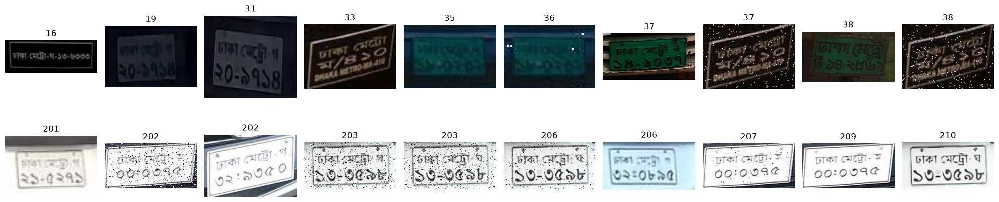

In [90]:
plate_samples = []

for label_file in train_label_dir.glob("*.txt"):
    text = label_file.read_text(encoding="utf-8").strip()

    if not text or label_file.stem not in image_map:
        continue

    image = Image.open(image_map[label_file.stem]).convert("RGB")
    img_w, img_h = image.size

    for box_id, line in enumerate(text.splitlines()):
        parts = line.split()

        if len(parts) != 5:
            continue

        _, xc, yc, w, h = map(float, parts)

        x1 = max(0, int((xc - w / 2) * img_w))
        y1 = max(0, int((yc - h / 2) * img_h))
        x2 = min(img_w, int((xc + w / 2) * img_w))
        y2 = min(img_h, int((yc + h / 2) * img_h))

        if x2 <= x1 or y2 <= y1:
            continue

        crop = image.crop((x1, y1, x2, y2))

        brightness = float(
            np.array(crop.convert("L")).mean()
        )

        plate_samples.append(
            (brightness, label_file.stem, box_id, crop.copy())
        )

plate_samples.sort(key=lambda x: x[0])

darkest = plate_samples[:10]
brightest = plate_samples[-10:]

fig, axes = plt.subplots(2, 10, figsize=(20, 5))

for ax, (brightness, name, box_id, crop) in zip(axes[0], darkest):
    ax.imshow(crop)
    ax.set_title(f"{brightness:.0f}")
    ax.axis("off")

for ax, (brightness, name, box_id, crop) in zip(axes[1], brightest):
    ax.imshow(crop)
    ax.set_title(f"{brightness:.0f}")
    ax.axis("off")

axes[0, 0].set_ylabel("Darkest", fontsize=12)
axes[1, 0].set_ylabel("Brightest", fontsize=12)

plt.tight_layout()
plt.show()

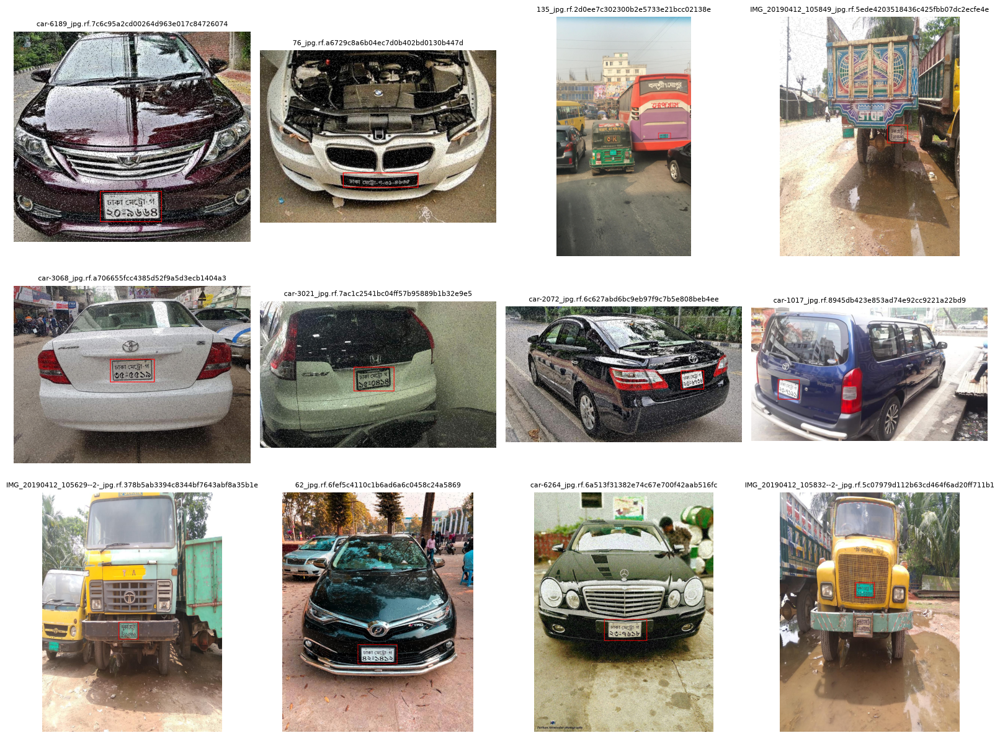

In [91]:
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

positive_labels = []

for label_file in train_label_dir.glob("*.txt"):
    if label_file.read_text(encoding="utf-8").strip():
        if label_file.stem in image_map:
            positive_labels.append(label_file)

random.seed(42)
selected = random.sample(positive_labels, 12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, label_file in zip(axes.flat, selected):

    image = Image.open(
        image_map[label_file.stem]
    ).convert("RGB")

    draw = ImageDraw.Draw(image)

    img_w, img_h = image.size

    lines = label_file.read_text(
        encoding="utf-8"
    ).strip().splitlines()

    for line in lines:

        parts = line.split()

        if len(parts) != 5:
            continue

        _, xc, yc, w, h = map(float, parts)

        x1 = (xc - w / 2) * img_w
        y1 = (yc - h / 2) * img_h
        x2 = (xc + w / 2) * img_w
        y2 = (yc + h / 2) * img_h

        draw.rectangle(
            [x1, y1, x2, y2],
            outline="red",
            width=max(2, img_w // 300)
        )

    ax.imshow(image)
    ax.set_title(label_file.stem, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

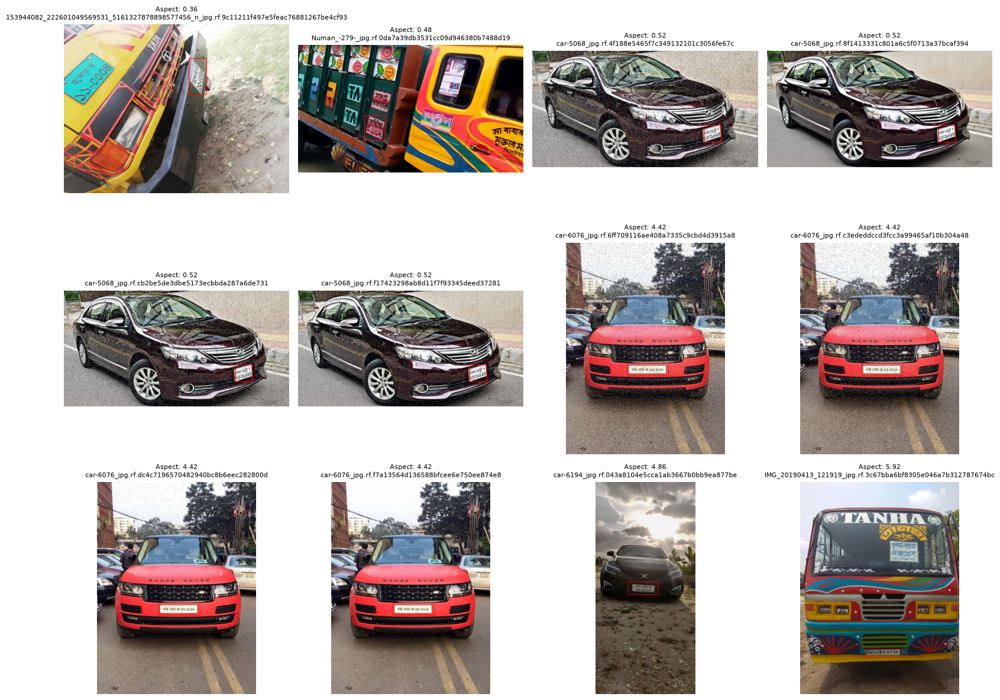

In [92]:
box_records = []

for label_file in train_label_dir.glob("*.txt"):
    text = label_file.read_text(encoding="utf-8").strip()

    if not text or label_file.stem not in image_map:
        continue

    for box_id, line in enumerate(text.splitlines()):
        parts = line.split()

        if len(parts) != 5:
            continue

        _, xc, yc, w, h = map(float, parts)

        if h > 0:
            box_records.append(
                (w / h, label_file, box_id, xc, yc, w, h)
            )

box_records.sort(key=lambda x: x[0])

selected = box_records[:6] + box_records[-6:]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, record in zip(axes.flat, selected):

    aspect, label_file, box_id, xc, yc, w, h = record

    image = Image.open(
        image_map[label_file.stem]
    ).convert("RGB")

    img_w, img_h = image.size

    x1 = (xc - w / 2) * img_w
    y1 = (yc - h / 2) * img_h
    x2 = (xc + w / 2) * img_w
    y2 = (yc + h / 2) * img_h

    draw = ImageDraw.Draw(image)

    draw.rectangle(
        [x1, y1, x2, y2],
        outline="red",
        width=max(2, img_w // 300)
    )

    ax.imshow(image)
    ax.set_title(
        f"Aspect: {aspect:.2f}\n{label_file.stem}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [93]:
aspects = np.array([record[0] for record in box_records])

print("LOCALIZATION ASPECT-RATIO DISTRIBUTION")
print("======================================")

print("Total boxes:", len(aspects))

print("\nVery narrow (< 0.75):",
      int(np.sum(aspects < 0.75)))

print("Narrow (< 1.0):",
      int(np.sum(aspects < 1.0)))

print("Typical (1.0 - 2.5):",
      int(np.sum((aspects >= 1.0) & (aspects <= 2.5))))

print("Wide (> 2.5):",
      int(np.sum(aspects > 2.5)))

print("Very wide (> 3.5):",
      int(np.sum(aspects > 3.5)))

print("\nPercentiles:")
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    print(
        f"{p:>2}%:",
        round(float(np.percentile(aspects, p)), 3)
    )

LOCALIZATION ASPECT-RATIO DISTRIBUTION
Total boxes: 3798

Very narrow (< 0.75): 157
Narrow (< 1.0): 544
Typical (1.0 - 2.5): 2931
Wide (> 2.5): 323
Very wide (> 3.5): 27

Percentiles:
 1%: 0.583
 5%: 0.772
10%: 0.903
25%: 1.193
50%: 1.517
75%: 1.969
90%: 2.43
95%: 2.692
99%: 3.258


In [94]:
area_values = np.array(box_areas)

print("LOCALIZATION PLATE SIZE DISTRIBUTION")
print("====================================")

print("Total boxes:", len(area_values))

print("\nVery small (< 0.5% image area):",
      int(np.sum(area_values < 0.005)))

print("Small (0.5% - 1%):",
      int(np.sum((area_values >= 0.005) & (area_values < 0.01))))

print("Medium (1% - 3%):",
      int(np.sum((area_values >= 0.01) & (area_values < 0.03))))

print("Large (3% - 10%):",
      int(np.sum((area_values >= 0.03) & (area_values < 0.10))))

print("Very large (>= 10%):",
      int(np.sum(area_values >= 0.10)))

print("\nPercentiles:")

for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    value = float(np.percentile(area_values, p))

    print(
        f"{p:>2}%:",
        round(value, 4),
        f"({value * 100:.2f}%)"
    )

LOCALIZATION PLATE SIZE DISTRIBUTION
Total boxes: 3798

Very small (< 0.5% image area): 154
Small (0.5% - 1%): 613
Medium (1% - 3%): 2246
Large (3% - 10%): 772
Very large (>= 10%): 13

Percentiles:
 1%: 0.0028 (0.28%)
 5%: 0.0055 (0.55%)
10%: 0.0071 (0.71%)
25%: 0.0112 (1.12%)
50%: 0.018 (1.80%)
75%: 0.0276 (2.76%)
90%: 0.0385 (3.85%)
95%: 0.0439 (4.39%)
99%: 0.0603 (6.03%)


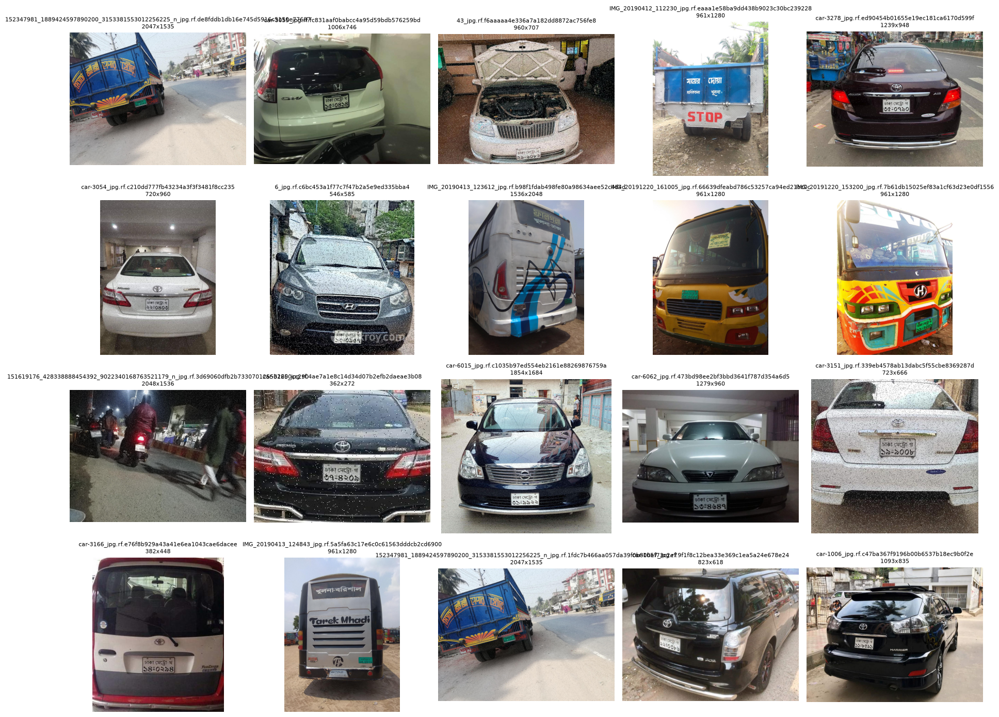

In [95]:
random.seed(123)

selected_labels = random.sample(
    positive_labels,
    min(20, len(positive_labels))
)

fig, axes = plt.subplots(4, 5, figsize=(18, 14))

for ax, label_file in zip(axes.flat, selected_labels):

    image = Image.open(
        image_map[label_file.stem]
    ).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f"{label_file.stem}\n{image.width}x{image.height}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [96]:
resolution_records = []

for image_path in image_map.values():
    with Image.open(image_path) as img:
        w, h = img.size

    resolution_records.append((w, h, w * h))

widths = np.array([x[0] for x in resolution_records])
heights = np.array([x[1] for x in resolution_records])
pixels = np.array([x[2] for x in resolution_records])

print("TRAINING IMAGE RESOLUTION ANALYSIS")
print("==================================")
print("Images:", len(resolution_records))

print("\nWidth:")
print("Min:", widths.min())
print("Median:", int(np.median(widths)))
print("Max:", widths.max())

print("\nHeight:")
print("Min:", heights.min())
print("Median:", int(np.median(heights)))
print("Max:", heights.max())

print("\nLow-resolution images:")
print(
    "<= 300 px on longest side:",
    int(np.sum(np.maximum(widths, heights) <= 300))
)

print(
    "<= 500 px on longest side:",
    int(np.sum(np.maximum(widths, heights) <= 500))
)

print(
    "<= 640 px on longest side:",
    int(np.sum(np.maximum(widths, heights) <= 640))
)

print("\nMegapixel percentiles:")

mp = pixels / 1_000_000

for p in [1, 5, 25, 50, 75, 95, 99]:
    print(
        f"{p:>2}%:",
        round(float(np.percentile(mp, p)), 3),
        "MP"
    )

TRAINING IMAGE RESOLUTION ANALYSIS
Images: 5124

Width:
Min: 261
Median: 960
Max: 2048

Height:
Min: 182
Median: 799
Max: 2048

Low-resolution images:
<= 300 px on longest side: 1
<= 500 px on longest side: 152
<= 640 px on longest side: 603

Megapixel percentiles:
 1%: 0.13 MP
 5%: 0.23 MP
25%: 0.518 MP
50%: 0.742 MP
75%: 1.23 MP
95%: 3.142 MP
99%: 3.146 MP


In [97]:
plate_pixel_widths = []
plate_pixel_heights = []

for label_file in train_label_dir.glob("*.txt"):
    text = label_file.read_text(encoding="utf-8").strip()

    if not text or label_file.stem not in image_map:
        continue

    with Image.open(image_map[label_file.stem]) as img:
        img_w, img_h = img.size

    for line in text.splitlines():
        parts = line.split()

        if len(parts) != 5:
            continue

        _, xc, yc, w, h = map(float, parts)

        plate_pixel_widths.append(w * img_w)
        plate_pixel_heights.append(h * img_h)

pw = np.array(plate_pixel_widths)
ph = np.array(plate_pixel_heights)

print("TRAINING PLATE PIXEL-SIZE ANALYSIS")
print("==================================")
print("Total boxes:", len(pw))

print("\nPlate width:")
print("Min:", round(float(pw.min()), 1), "px")
print("Median:", round(float(np.median(pw)), 1), "px")
print("Max:", round(float(pw.max()), 1), "px")

print("\nPlate height:")
print("Min:", round(float(ph.min()), 1), "px")
print("Median:", round(float(np.median(ph)), 1), "px")
print("Max:", round(float(ph.max()), 1), "px")

print("\nSmall plate counts:")
print(
    "Width < 100 px:",
    int(np.sum(pw < 100))
)

print(
    "Height < 50 px:",
    int(np.sum(ph < 50))
)

print(
    "Width < 100 AND height < 50:",
    int(np.sum((pw < 100) & (ph < 50)))
)

print("\nWidth percentiles:")
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    print(
        f"{p:>2}%:",
        round(float(np.percentile(pw, p)), 1),
        "px"
    )

TRAINING PLATE PIXEL-SIZE ANALYSIS
Total boxes: 3798

Plate width:
Min: 41.0 px
Median: 148.0 px
Max: 605.0 px

Plate height:
Min: 25.0 px
Median: 88.5 px
Max: 638.0 px

Small plate counts:
Width < 100 px: 619
Height < 50 px: 204
Width < 100 AND height < 50: 186

Width percentiles:
 1%: 59.9 px
 5%: 80.0 px
10%: 91.0 px
25%: 112.0 px
50%: 148.0 px
75%: 187.0 px
90%: 237.0 px
95%: 283.1 px
99%: 424.3 px


In [98]:
summary_path = (
    project_root
    / "results"
    / "localization_dataset_diagnosis.txt"
)

summary_path.parent.mkdir(parents=True, exist_ok=True)

summary = """LOCALIZATION DATASET DIAGNOSIS

Dataset:
Train images: 5124
Positive images: 3745
Negative images: 1379
Annotated boxes: 3798

Brightness:
Dark: 568 (14.96%)
Medium: 2970 (78.20%)
Bright: 260 (6.85%)

Bounding boxes:
Median normalized width: 0.1678
Median normalized height: 0.1094
Median area: 1.80%
Median aspect ratio: 1.517

Aspect ratio:
Very narrow (<0.75): 157
Typical (1.0-2.5): 2931
Very wide (>3.5): 27
Visual inspection showed a mixture of genuine unusual plates
and some questionable/tight annotations.

Image resolution:
Median width: 960 px
Median height: 799 px
Only 152 images have longest side <=500 px.
Only 603 images have longest side <=640 px.

Actual plate size:
Median plate width: 148 px
Median plate height: 88.5 px
619 plates are below 100 px wide.
186 plates are below 100 px wide and 50 px high.

Visual diversity:
Moderate diversity was observed.
Many images use similar front/rear viewpoints, daylight conditions,
centered plate positions, and similar vehicle-to-camera distances.

Unseen-test evidence:
Test 01: success
Test 02: success after merging overlapping detections
Test 03: localization failure
Test 04: localization failure
Test 05: weak localization / partial recognition
Test 06: localization box substantially shifted

Conclusion:
The primary bottleneck is localization generalization.
Low resolution contributes to some failures, especially Test 03.
Brightness alone does not explain the failures.
Plate size alone does not explain the failures.
Some annotation inconsistencies exist but are not sufficient by
themselves to explain the unseen-test behavior.
The training dataset has moderate domain diversity and appears
underrepresented in difficult viewpoints, lighting, distances,
low-resolution conditions, and other unseen-domain situations.

Recommended next phase:
Improve localization training data and augmentation before retraining.
Do not simply retrain the existing YOLO11n configuration unchanged.
"""

summary_path.write_text(summary, encoding="utf-8")

print("DIAGNOSIS SAVED")
print("================")
print(summary_path)
print("Exists:", summary_path.exists())

DIAGNOSIS SAVED
D:\Documents\Ml project\Bangladesh_License_Plate_Recognition\results\localization_dataset_diagnosis.txt
Exists: True
